ALDANA: hace Ctrl+Shift+P → Developer: Reload Window. Sino no anda.

##### Librerías

In [ ]:
import time
import numpy as np
import pandas as pd
import seaborn as sns
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from adjustText import adjust_text
from geopy.geocoders import ArcGIS
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler # Para estandarización de datos
from sklearn.model_selection import train_test_split # Para separar en train test
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, roc_auc_score, roc_curve,
                             confusion_matrix, ConfusionMatrixDisplay)


## Dataset

In [47]:
# Lectura de dataset
df = pd.read_csv('weatherAUS_2026C2.csv')
df.head()

,Unnamed: 0,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
0,0,2008-12-01,Albury,13.6,22.5,0.6,NaN,NaN,W,45.0,...,23.8,1008.1,1007.2,8.0,NaN,16.8,20.8,No,No,0.0
1,1,2008-12-02,Albury,7.3,25.8,0.0,NaN,NaN,WNW,44.0,...,22.1,1011.1,1007.5,NaN,NaN,18.3,24.6,No,No,0.0
2,2,2008-12-03,Albury,13.2,26.2,0.0,NaN,NaN,WSW,46.0,...,31.5,1007.3,1009.4,NaN,2.0,21.2,23.4,No,No,0.0
3,3,2008-12-04,Albury,10.0,28.8,0.0,NaN,NaN,NE,23.0,...,18.5,1017.6,1012.4,NaN,NaN,17.4,26.3,No,No,1.0
4,4,2008-12-05,Albury,17.4,32.4,1.0,NaN,NaN,W,41.0,...,34.6,1010.9,1005.9,7.0,8.0,17.9,29.1,No,No,0.2


### Descripcion

In [3]:
# Medidas del dataset (filas, columnas)
df.shape

(145412, 25)

In [4]:
# Medidas estadísticas principales del dataset
df.describe()

,Unnamed: 0,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainfallTomorrow
count,145412.000000,143928.000000,144159.000000,142152.000000,82658.000000,75616.000000,135159.000000,143645.000000,142351.000000,142759.000000,140907.000000,130351.000000,130388.000000,89542.000000,86076.000000,143646.000000,141805.000000,142153.000000
mean,72728.184393,12.196528,23.223064,2.361516,5.468616,7.611241,40.036668,14.067277,18.661899,68.861521,51.532206,1017.647237,1015.255080,4.447287,4.509770,16.991981,21.683360,2.361242
std,41990.722236,6.417956,7.135927,8.479338,4.193871,3.785612,13.648259,8.936768,8.865457,19.062866,20.844414,7.113833,7.044507,2.887161,2.720306,6.509191,6.953072,8.479084
min,0.000000,-9.700000,-5.100000,0.000000,0.000000,0.000000,6.000000,0.000000,0.000000,0.000000,0.000000,980.300000,977.400000,0.000000,0.000000,-8.000000,-5.800000,0.000000
25%,36362.750000,7.600000,17.900000,0.000000,2.600000,4.800000,31.000000,7.000000,12.000000,57.000000,36.600000,1012.900000,1010.400000,1.000000,2.000000,12.300000,16.600000,0.000000
50%,72727.500000,12.000000,22.600000,0.000000,4.800000,8.400000,38.000000,13.000000,18.000000,69.900000,52.000000,1017.600000,1015.200000,5.000000,5.000000,16.700000,21.100000,0.000000
75%,109093.250000,16.900000,28.200000,0.800000,7.400000,10.600000,48.000000,19.000000,24.000000,83.100000,65.700000,1022.400000,1020.000000,7.000000,7.000000,21.600000,26.400000,0.800000
max,145458.000000,34.100000,49.100000,371.000000,145.000000,14.500000,135.000000,130.000000,86.000000,100.000000,100.000000,1041.200000,1039.800000,9.000000,9.000000,39.800000,47.000000,371.000000


In [5]:
# Tipos de datos, valores no nulos, nulos y porcentaje de nulos.

# Como df.info() no muestra todas las columnas ya que sobrepasa el límite de filas, 
# se utiliza pd.option_context para mostrar todas las columnas y sus tipos de datos.

with pd.option_context('display.max_rows', None):
    display(pd.DataFrame({
        'no_nulos': df.count(),
        'nulos': df.isna().sum(),
        'dtype': df.dtypes,
        '%_nulos': (df.isna().mean() * 100).round(2)}))

,no_nulos,nulos,dtype,%_nulos
Unnamed: 0,145412,0,int64,0.00
Date,145412,0,str,0.00
Location,145412,0,str,0.00
MinTemp,143928,1484,float64,1.02
MaxTemp,144159,1253,float64,0.86
Rainfall,142152,3260,float64,2.24
Evaporation,82658,62754,float64,43.16
Sunshine,75616,69796,float64,48.00
WindGustDir,135096,10316,str,7.09
WindGustSpeed,135159,10253,float64,7.05


Notamos de este primer vistazo que las siguientes columnas tienen menos de un 5% faltante:
- Unnamed (correspondiente al índice)
- Date
- Location
- MinTemp
- MaxTemp
- Rainfall
- WindDir3pm
- WindSpeed9am
- WindSpeed3pm
- Humidity9am
- Humidity3pm
- Temp9am
- Temp3pm
- RainToday
- RainTomorrow
- RainfallTomorrow

Las siguientes columnas tienen un faltante de aproximadamente 10%:
- WindGustDir
- WindGustSpeed
- WindDir9am
- Pressure9am
- Pressure3pm

Y por ultimo estas variables poseen una falta de hasta un 50%:
- Evaporation
- Sunshine
- Cloud9am
- Cloud3pm

Hasta el momento sabemos que es un dataset que juntó datos diarios sobre el clima en Australia, y que busca predecir si al día siguiente lloverá o no. 
Para aprender mas al respecto, aplicaremos algunas funciones a las variables hasta dar con la información exacta que brinda cada columna:

In [6]:
### Date
# Para descubrir el primer día que se tomaron mediciones y el ultimo,
# convertimos la columna 'Date' a tipo datetime y luego usamos min() y max() para obtener las fechas.
df['Date'] = pd.to_datetime(df['Date'])
first_date = df['Date'].min()
last_date = df['Date'].max()

print(f"Primer día de mediciones: {first_date}")
print(f"Último día de mediciones: {last_date}")

Primer día de mediciones: 2007-11-01 00:00:00
Último día de mediciones: 2017-06-24 00:00:00


In [7]:
### Location
# Para hallar las locaciones, utilizamos unique().
locations = df['Location'].unique()

print(locations) # son 49

<StringArray>
[          'Albury',    'BadgerysCreek',            'Cobar',
     'CoffsHarbour',            'Moree',        'Newcastle',
        'NorahHead',    'NorfolkIsland',          'Penrith',
         'Richmond',           'Sydney',    'SydneyAirport',
       'WaggaWagga',      'Williamtown',       'Wollongong',
         'Canberra',      'Tuggeranong',      'MountGinini',
         'Ballarat',          'Bendigo',             'Sale',
 'MelbourneAirport',        'Melbourne',          'Mildura',
             'Nhil',         'Portland',         'Watsonia',
         'Dartmoor',         'Brisbane',           'Cairns',
        'GoldCoast',       'Townsville',         'Adelaide',
     'MountGambier',        'Nuriootpa',          'Woomera',
           'Albany',      'Witchcliffe',       'PearceRAAF',
     'PerthAirport',            'Perth',       'SalmonGums',
          'Walpole',           'Hobart',       'Launceston',
     'AliceSprings',           'Darwin',        'Katherine',
          

In [8]:
### WindGustDir
# Para hallar las locaciones, utilizamos unique().
WindGustDir = df['WindGustDir'].unique()

print(WindGustDir) # son 16 sin contar Nan.

# Las mismas entradas, correspondientes a cardinalidad, se repiten en la columna WindDir9am y WindDir3pm.

<StringArray>
[  'W', 'WNW', 'WSW',  'NE', 'NNW',   'N', 'NNE',  'SW',   nan, 'ENE', 'SSE',
   'S',  'NW',  'SE', 'ESE',   'E', 'SSW']
Length: 17, dtype: str


In [9]:
### RainToday y RainTomorrow
# Sospechamos que son categoricas, por lo que procedemos a corroborarlo:
rain_today = df['RainToday'].unique()
rain_tomorrow = df['RainTomorrow'].unique()

print(rain_today)
print(rain_tomorrow) # Ambas son categoricas binarias, sin incluir el Nan.

<StringArray>
['No', 'Yes', nan]
Length: 3, dtype: str
<StringArray>
['No', 'Yes', nan]
Length: 3, dtype: str


In [10]:
### Cloud9am y Cloud3pm
# Sospechamos que son categoricas, por lo que procedemos a corroborarlo:
cloud_9am = df['Cloud9am'].unique()
cloud_3pm = df['Cloud3pm'].unique()

print(cloud_9am)
print(cloud_3pm) # Ambas son categoricas (numericas pero discretas) del 0 al 9, sin incluir el Nan.   

# Para saber cuántas veces aparece cada valor en el dataset:
cloud_9am_count = df['Cloud9am'].value_counts()
cloud_3pm_count = df['Cloud3pm'].value_counts()

print(cloud_9am_count)
print("\n------------\n")
print(cloud_3pm_count)
# 9 aparece solo 3 veces sumando ambas.
# Según la Organización Meteorológica Mundial (OMM), significa Cielo obstruido / Invisible.

[ 8. nan  7.  1.  0.  5.  4.  2.  6.  3.  9.]
[nan  2.  8.  7.  1.  5.  4.  6.  3.  0.  9.]
Cloud9am
7.0    19965
1.0    15680
8.0    14690
0.0     8641
6.0     8168
2.0     6500
3.0     5912
5.0     5566
4.0     4418
9.0        2
Name: count, dtype: int64

------------

Cloud3pm
7.0    18226
1.0    14972
8.0    12650
6.0     8978
2.0     7224
3.0     6915
5.0     6815
4.0     5321
0.0     4974
9.0        1
Name: count, dtype: int64


En base a lo obtenido, podemos afirmar que el dataset contiene observaciones meteorológicas diarias de 49 estaciones de Australia, entre el 01/11/2007 y el 24/06/2017. Cada fila representa un día en una cierta ubicación, y reúne mediciones de temperatura, lluvia, viento, humedad, presión y nubosidad. El objetivo es predecir si lloverá al día siguiente (`RainTomorrow`).

| Variable | Significado | Unidad | Tipo | Rango observado |
|---|---|---|---|---|
| `Date` | Fecha de la observación | AAAA-MM-DD | Fecha (texto) | 2007-11-01 a 2017-06-24 |
| `Location` | Estación meteorológica | – | Categórica | 49 ubicaciones |
| `MinTemp` | Temperatura mínima del día | °C | Numérica continua | -9,7 a 34,1 |
| `MaxTemp` | Temperatura máxima del día | °C | Numérica continua | -5,1 a 49,1 |
| `Rainfall` | Lluvia caída en el día | mm | Numérica continua | 0 a 371 |
| `Evaporation` | Evaporación (tanque clase A) en las 24 h previas a las 9am | mm | Numérica continua | 0 a 145 |
| `Sunshine` | Horas de sol brillante en el día | horas | Numérica continua | 0 a 14,5 |
| `WindGustDir` | Dirección de la ráfaga de viento más fuerte del día | Punto cardinal | Categórica (16 valores) | N, NNE, NE, ..., NNW |
| `WindGustSpeed` | Velocidad de la ráfaga más fuerte del día | km/h | Numérica continua | 6 a 135 |
| `WindDir9am` | Dirección del viento a las 9am | Punto cardinal | Categórica (16 valores) | N, NNE, NE, ..., NNW |
| `WindDir3pm` | Dirección del viento a las 3pm | Punto cardinal | Categórica (16 valores) | N, NNE, NE, ..., NNW |
| `WindSpeed9am` | Velocidad media del viento a las 9am | km/h | Numérica continua | 0 a 130 |
| `WindSpeed3pm` | Velocidad media del viento a las 3pm | km/h | Numérica continua | 0 a 86 |
| `Humidity9am` | Humedad relativa a las 9am | % | Numérica continua | 0 a 100 |
| `Humidity3pm` | Humedad relativa a las 3pm | % | Numérica continua | 0 a 100 |
| `Pressure9am` | Presión atmosférica a las 9am | hPa | Numérica continua | 980,3 a 1041,2 |
| `Pressure3pm` | Presión atmosférica a las 3pm | hPa | Numérica continua | 977,4 a 1039,8 |
| `Cloud9am` | Fracción del cielo cubierta por nubes a las 9am | Octas | Numérica discreta | 0 a 9 |
| `Cloud3pm` | Fracción del cielo cubierta por nubes a las 3pm | Octas | Numérica discreta | 0 a 9 |
| `Temp9am` | Temperatura a las 9am | °C | Numérica continua | -8,0 a 39,8 |
| `Temp3pm` | Temperatura a las 3pm | °C | Numérica continua | -5,8 a 47,0 |
| `RainToday` | Indica si llovió hoy (`Rainfall` > 1 mm) | Yes/No | Categórica binaria | Yes, No |
| `RainTomorrow` | Indica si lloverá mañana (**variable objetivo**) | Yes/No | Categórica binaria | Yes, No |
| `RainfallTomorrow` | Lluvia caída al día siguiente | mm | Numérica continua | 0 a 371 |

**Observaciones:**
- `RainToday` vale "Yes" cuando `Rainfall` > 1 mm
- `RainTomorrow` vale "Yes" cuando `RainfallTomorrow` > 1 mm.

- Por lo anterior, `RainfallTomorrow` contiene exactamente la información del target. No debe usarse como variable predictora, ya que provocaría *data leakage*.
- En `Cloud9am` y `Cloud3pm` la escala de octas va de 0 a 8; el valor 9 (presente solo en 2 registros de `Cloud9am`) indica cielo no visible.
- `Rainfall` (máx. 371 mm), `Evaporation` (máx. 145 mm) y `WindSpeed9am` (máx. 130 km/h) tienen valores máximos muy alejados del resto de la distribución, a revisar más adelante.

##### ¿El dataset está desbalanceado?

In [11]:
conteo = df['RainTomorrow'].value_counts(dropna=False)
prop = df['RainTomorrow'].value_counts(normalize=True, dropna=False) * 100

pd.DataFrame({'Cantidad': conteo, 'Proporción (%)': prop.round(1)})

,Cantidad,Proporción (%)
RainTomorrow,,
No,110281,75.8
Yes,31872,21.9
NaN,3259,2.2


La respuesta es sí, está bastante desvalanciado.

*¿Por qué esta pregunta?*
- La accuracy engaña. Un modelo que siempre prediga "No llueve" acierta cerca del 78%. Sin verificación, podríamos creer que un modelo mediocre es bueno.

Por ende hay que mirar precision, recall, F1, la matriz de confusión, la curva ROC/PR y el AUC, no solo la accuracy. En este problema suele importar más detectar bien los días de lluvia (la clase minoritaria).
- Afecta el entrenamiento. Los modelos tienden a favorecer la clase mayoritaria. Según el caso se puede usar class_weight='balanced', ajustar el umbral de decisión, o hacer over/undersampling (por ejemplo SMOTE).
- Afecta el split train/test. Conviene usar train_test_split(..., stratify=y) para que ambos conjuntos mantengan la misma proporción de clases. 

#### Gráficos descriptivos
##### 1. Boxplots e Histogramas (variables numericas continuas)

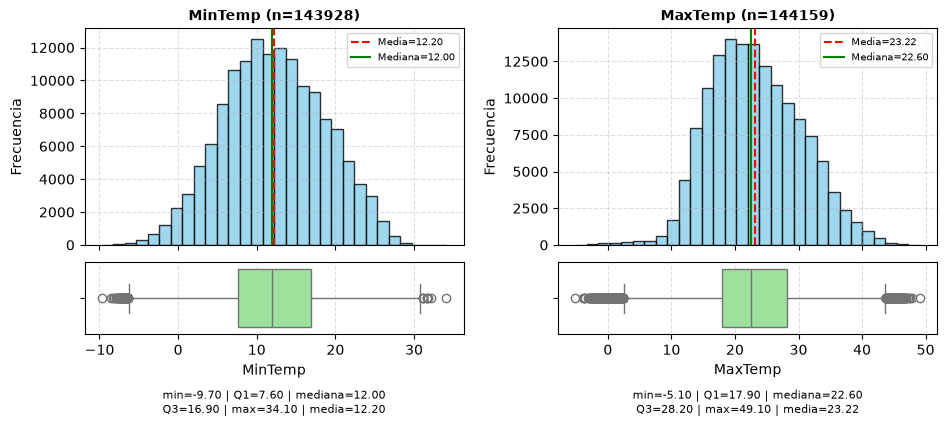

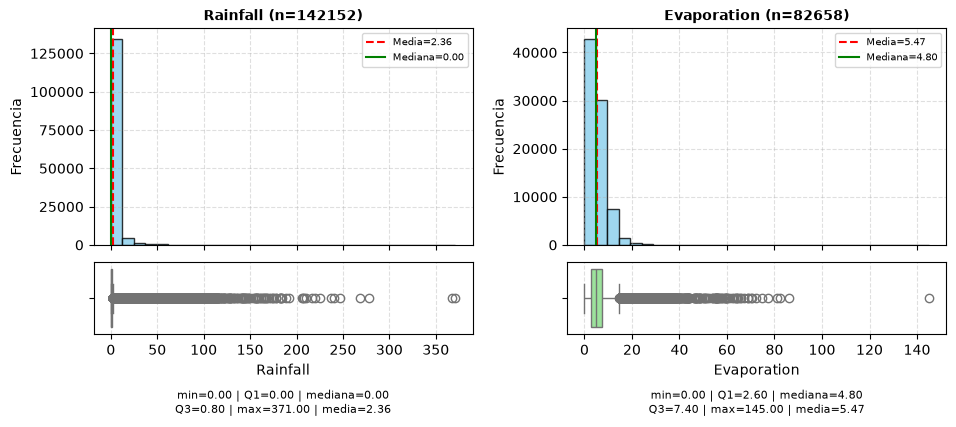

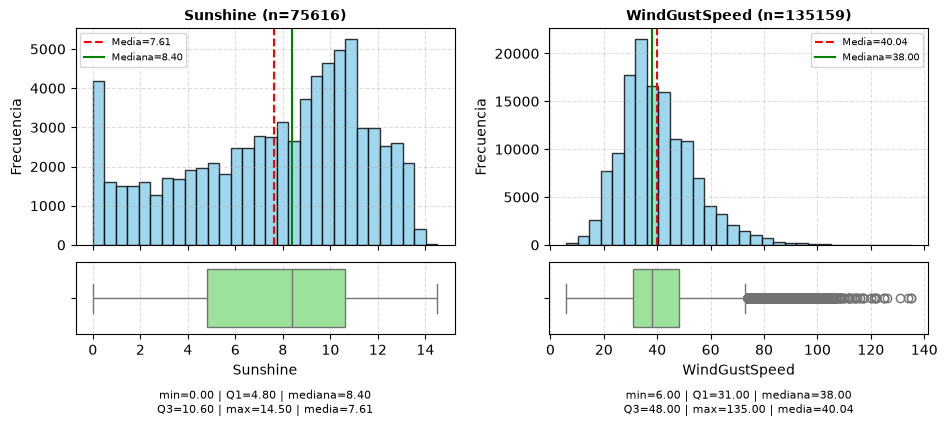

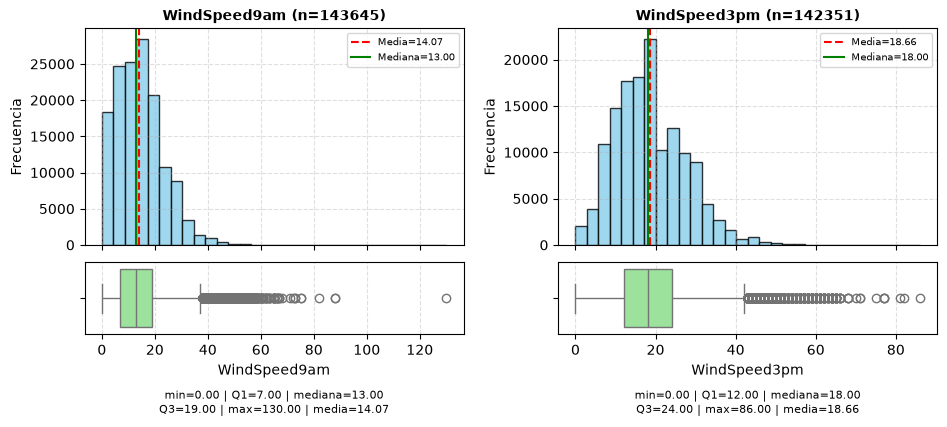

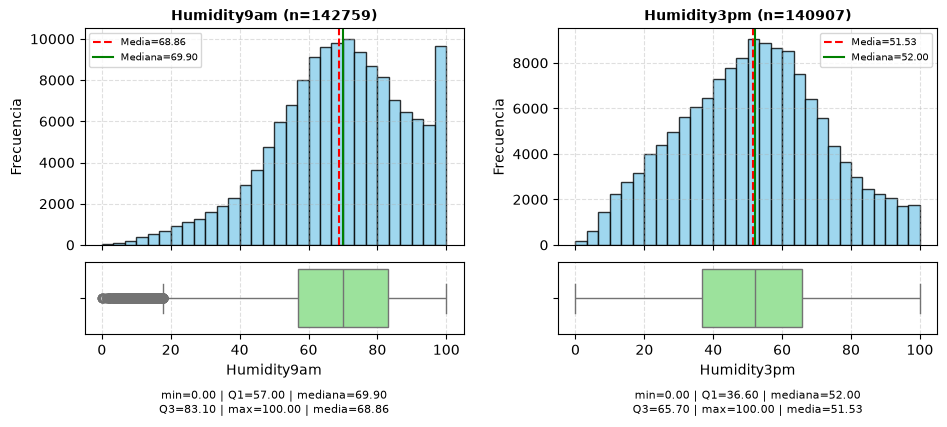

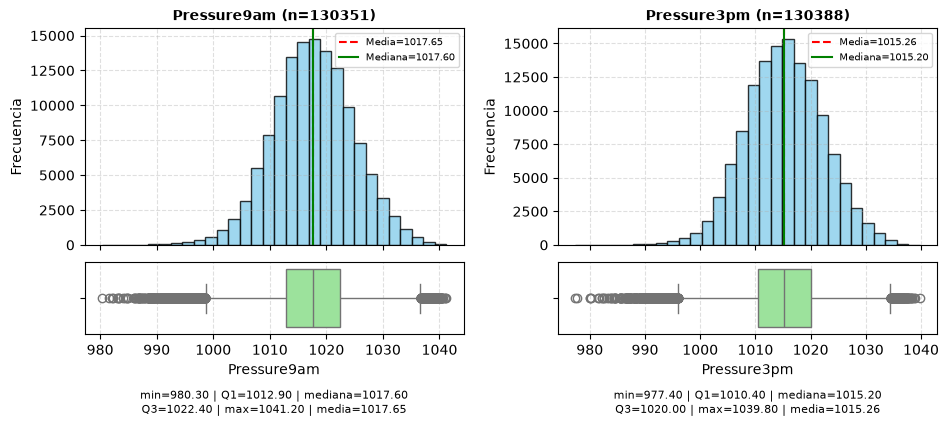

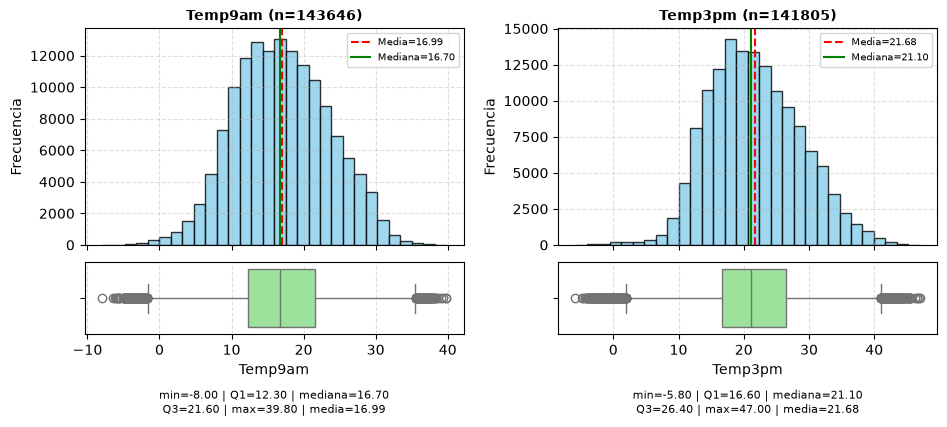

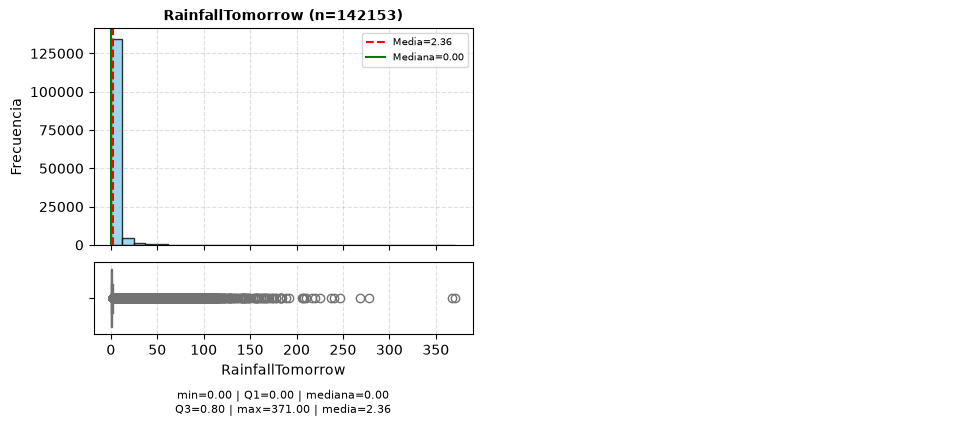

In [ ]:
# Variables numéricas del dataset
variables_numericas = df.select_dtypes(include='number').columns.drop(['Unnamed: 0', 'Cloud3pm', 'Cloud9am'])
# Descartamos del listado la columna 'Unnamed: 0' ya que es un índice y no aporta información relevante.
# Tambien 'Cloud3pm' y 'Cloud9am' ya que son discretas. Haremos otros graficos con ellas.

# Se grafican de a 2 variables por figura (una al lado de la otra) para que entren en pantalla.
for inicio in range(0, len(variables_numericas), 2):
    par = variables_numericas[inicio:inicio + 2]

    fig, axes = plt.subplots(
        2, 2, figsize=(11, 4.5),
        gridspec_kw={'height_ratios': [3, 1], 'hspace': 0.12, 'wspace': 0.25}
    )

    for j, col in enumerate(par):
        ax_hist, ax_box = axes[0, j], axes[1, j]
        datos = df[col].dropna()
        ax_hist.sharex(ax_box)
        plt.setp(ax_hist.get_xticklabels(), visible=False)

        # Histograma
        ax_hist.hist(datos, bins=30, color='skyblue', edgecolor='black', alpha=0.8)
        ax_hist.axvline(datos.mean(), color='red', linestyle='--', linewidth=1.5,
                        label=f'Media={datos.mean():.2f}')
        ax_hist.axvline(datos.median(), color='green', linestyle='-', linewidth=1.5,
                        label=f'Mediana={datos.median():.2f}')
        ax_hist.set_title(f'{col} (n={len(datos)})', fontsize=10, fontweight='bold')
        ax_hist.set_ylabel('Frecuencia')
        ax_hist.grid(linestyle='--', alpha=0.4)
        ax_hist.legend(fontsize=7)

        # Boxplot
        sns.boxplot(x=datos, ax=ax_box, color='lightgreen')
        ax_box.set_xlabel(col)
        ax_box.grid(axis='x', linestyle='--', alpha=0.4)

        # Resumen numérico debajo del boxplot
        resumen = (f'min={datos.min():.2f} | Q1={datos.quantile(0.25):.2f} | '
                   f'mediana={datos.median():.2f}\nQ3={datos.quantile(0.75):.2f} | '
                   f'max={datos.max():.2f} | media={datos.mean():.2f}')
        ax_box.text(0.5, -0.75, resumen, ha='center', va='top', fontsize=8,
                    transform=ax_box.transAxes)

    # Si queda una sola variable en la última figura, se oculta el par de ejes vacío
    for j in range(len(par), 2):
        axes[0, j].axis('off')
        axes[1, j].axis('off')

    plt.subplots_adjust(bottom=0.2)
    plt.show()


Observamos que:
- Rainfall, Evaporation y RainfallTomorrow presentan distribuciones completamente asimétricas positivas (sesgo a la derecha).
- MinTemp, MaxTemp, Humidity3pm, Temp9am y Temp3pm poseen distribuciones aproximadamente normales.
- Sunshine y Humidity9am lucen bimodales.
- WindGustSpeed, WindSpeed9am y WindSpeed3pm se comporta casi de forma normal aun que presenta algunos putliers que dibujan una cola de asimetría hacia la derecha.
- Pressure9am y Pressure3pm exactamente lo mismo que las anteriores pero con una pequeña cola hacia la izquierda.

##### 2. Barras agrupadas con frecuencias (variables numericas discretas)

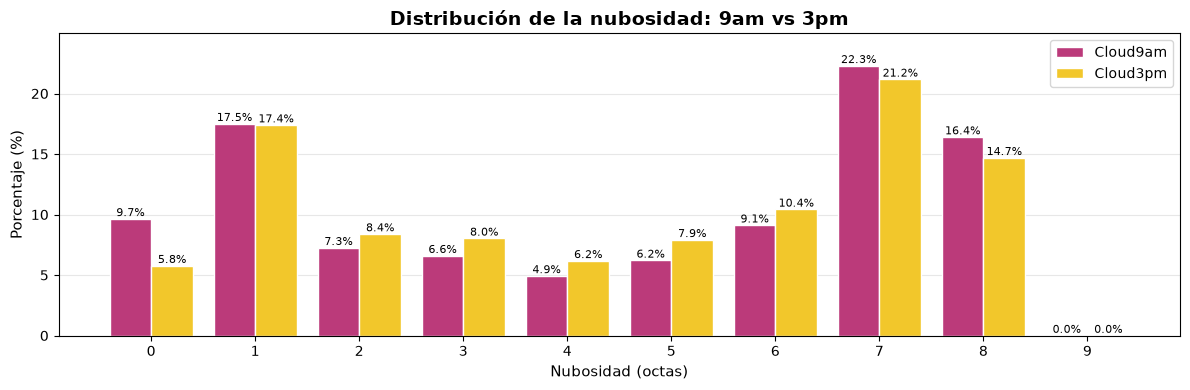

In [44]:
vars_nubes = ['Cloud9am', 'Cloud3pm']
colores_nubes = {'Cloud9am': "#BB3A7A", 'Cloud3pm': "#F2C72B"}

def graficar_frecuencia_discretas(df, columnas, colores, porcentaje=True):
    """Barras de frecuencia agrupadas para variables discretas: una barra por columna en cada valor."""
    niveles = sorted(set().union(*[df[c].dropna().unique() for c in columnas]))
    ancho = 0.8 / len(columnas)

    fig, ax = plt.subplots(figsize=(12, 4))
    for i, col in enumerate(columnas):
        conteo = df[col].value_counts().reindex(niveles, fill_value=0)
        valores = conteo / df[col].notna().sum() * 100 if porcentaje else conteo
        posiciones = np.arange(len(niveles)) + (i - (len(columnas) - 1) / 2) * ancho
        barras = ax.bar(posiciones, valores.values, width=ancho, color=colores[col],
                        edgecolor='white', label=col)
        for barra in barras:
            texto = f'{barra.get_height():.1f}%' if porcentaje else f'{int(barra.get_height())}'
            ax.annotate(texto, (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                        ha='center', va='bottom', fontsize=8)

    ax.set_xticks(np.arange(len(niveles)))
    ax.set_xticklabels([int(n) for n in niveles])
    ax.set_xlabel('Nubosidad (octas)', fontsize=11)
    ax.set_ylabel('Porcentaje (%)' if porcentaje else 'Frecuencia', fontsize=11)
    ax.set_title('Distribución de la nubosidad: 9am vs 3pm', fontsize=14, fontweight='bold')
    ax.grid(axis='y', alpha=0.3)
    ax.set_axisbelow(True)
    ax.margins(y=0.12)
    ax.legend()
    plt.tight_layout()
    plt.show()

graficar_frecuencia_discretas(df, vars_nubes, colores_nubes)

En ambas variables observamos mayor freceuncia de aparición del número 7, es decir que la octa numero 7 es la fracción de cielo cubierta por nubes con más aparicion de las 9 posibles.

##### 3. Barras (variables categóricas)

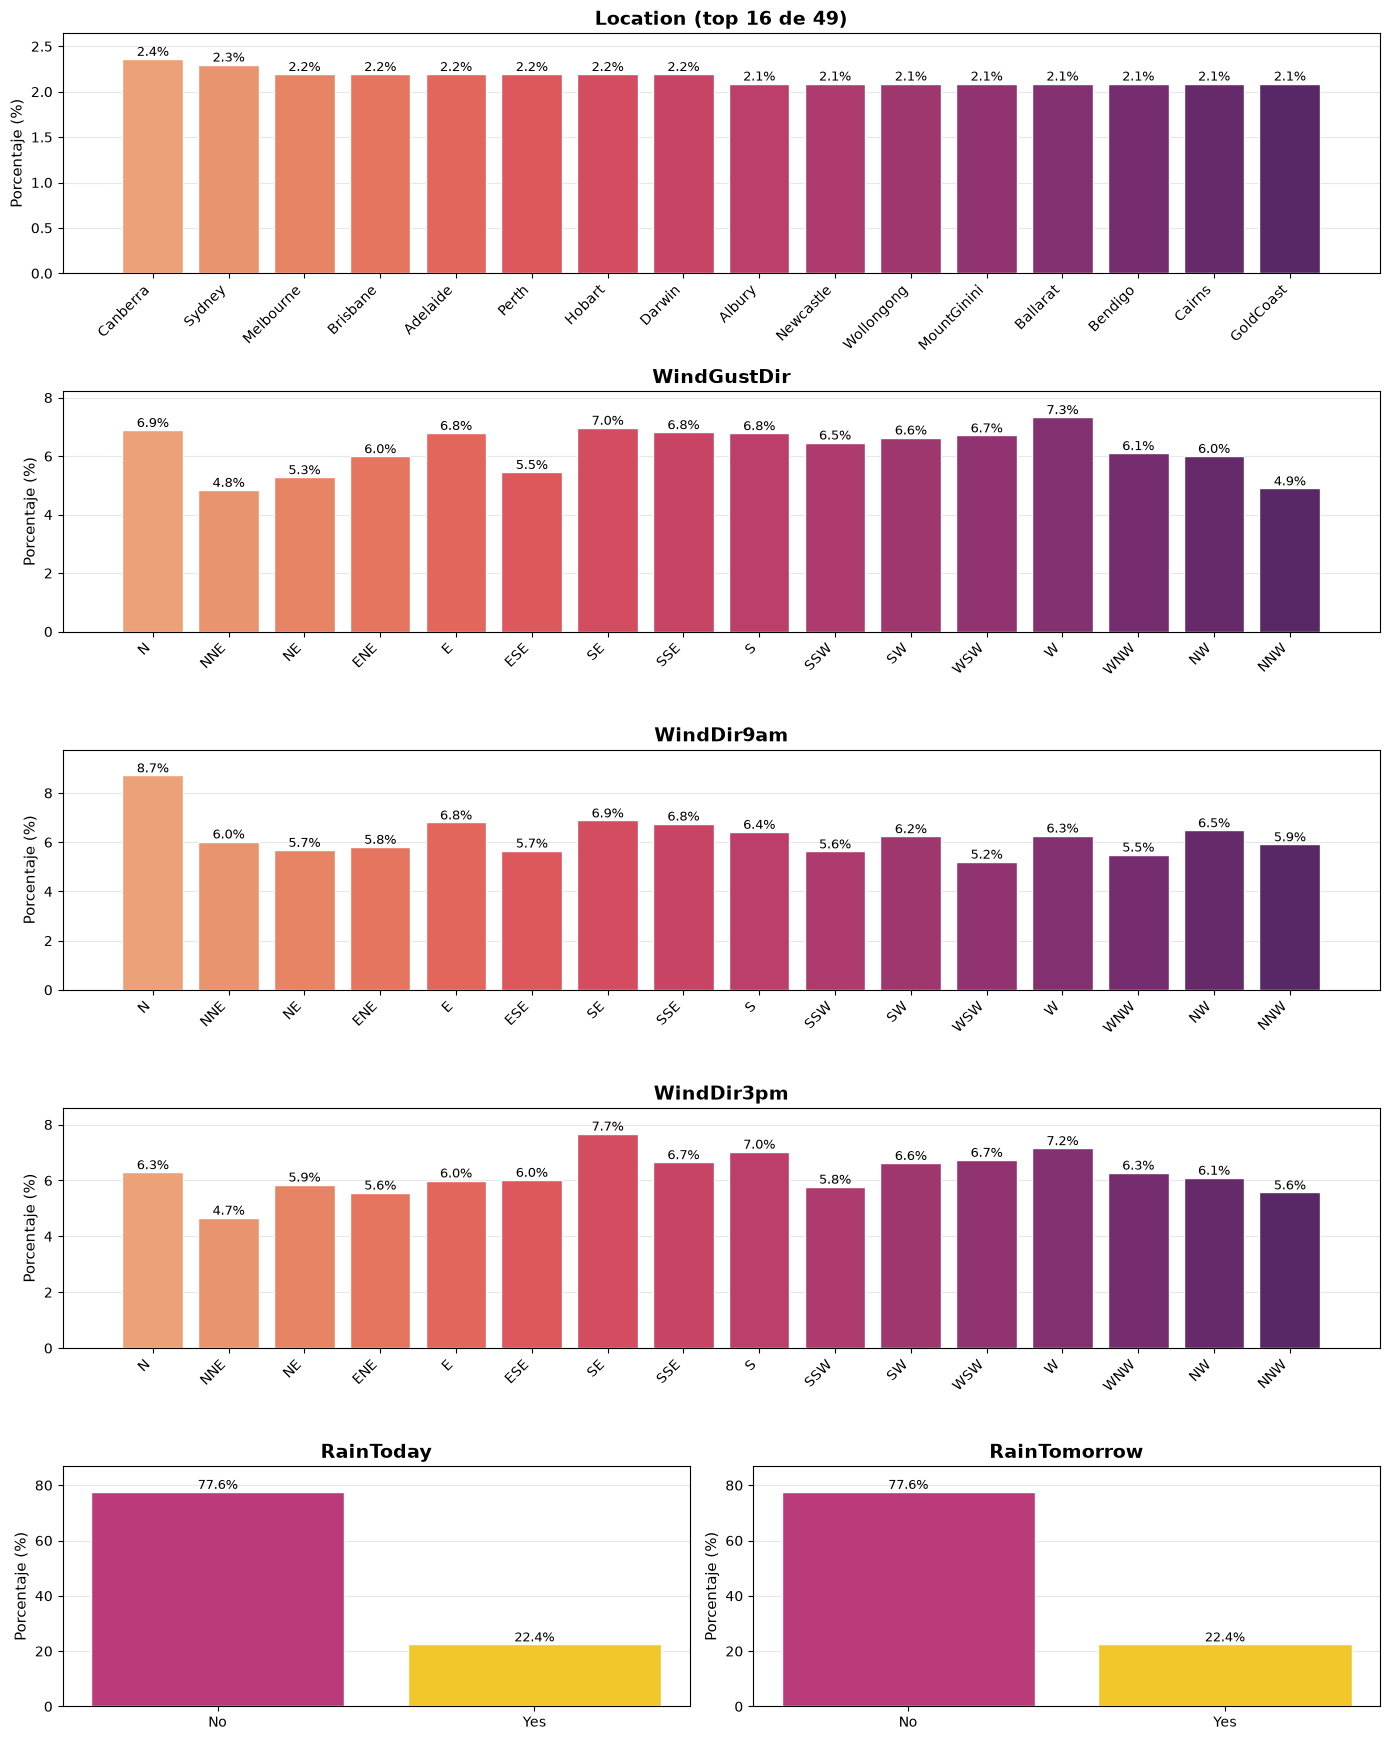

In [41]:
vars_categoricas = ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday', 'RainTomorrow']
vars_viento = ['WindGustDir', 'WindDir9am', 'WindDir3pm']
# Ordenamos los puntos cardinales segun como se encuentran en la brújula, 
# para que los gráficos de barras tengan un orden lógico.
orden_brujula = ['N', 'NNE', 'NE', 'ENE', 'E', 'ESE', 'SE', 'SSE',
                 'S', 'SSW', 'SW', 'WSW', 'W', 'WNW', 'NW', 'NNW']
colores_si_no = {'No': "#BB3A7A", 'Yes': "#F2C72B"}

def graficar_categoricas(df, columnas, top_n=16, porcentaje=True, alto_fila=3.5):
    """Gráfico de barras por variable categórica, con colores según el tipo de variable.
    - Viento: orden de brújula y paleta cíclica.
    - Variables Yes/No: se muestran de a dos, una al lado de la otra.
    - Resto (ej. Location): degradé por frecuencia, limitado a las top_n categorías."""
    es_binaria = lambda col: set(df[col].dropna().unique()) <= set(colores_si_no)
    otras = [c for c in columnas if not es_binaria(c)]
    binarias = [c for c in columnas if es_binaria(c)]

    # Cada variable no binaria ocupa una fila completa; las binarias se agrupan de a dos por fila
    filas_binarias = [binarias[i:i + 2] for i in range(0, len(binarias), 2)]
    n_filas = len(otras) + len(filas_binarias)
    fig = plt.figure(figsize=(14, alto_fila * n_filas))
    gs = fig.add_gridspec(n_filas, 2)

    ubicaciones = [(col, gs[i, :]) for i, col in enumerate(otras)]
    for i, fila in enumerate(filas_binarias, start=len(otras)):
        ubicaciones += [(col, gs[i, j]) for j, col in enumerate(fila)]

    for col, celda in ubicaciones:
        ax = fig.add_subplot(celda)
        conteo = df[col].value_counts()
        titulo = col

        if col in vars_viento:
            conteo = conteo.reindex(orden_brujula, fill_value=0)
            colores = sns.color_palette('flare', len(conteo))
        elif col in binarias:
            conteo = conteo.reindex(['No', 'Yes'], fill_value=0)
            colores = [colores_si_no[c] for c in conteo.index]
        else:
            if len(conteo) > top_n:
                titulo = f'{col} (top {top_n} de {len(conteo)})'
                conteo = conteo.head(top_n)
            colores = sns.color_palette('flare', len(conteo))

        valores = conteo / df[col].notna().sum() * 100 if porcentaje else conteo
        barras = ax.bar(valores.index.astype(str), valores.values, color=colores, edgecolor='white')

        ax.set_title(titulo, fontsize=14, fontweight='bold')
        ax.set_ylabel('Porcentaje (%)' if porcentaje else 'Frecuencia', fontsize=11)
        ax.tick_params(axis='x', rotation=0 if col in binarias else 45, labelsize=10)
        if col not in binarias:
            for etiqueta in ax.get_xticklabels():
                etiqueta.set_ha('right')
        ax.grid(axis='y', alpha=0.3)
        ax.set_axisbelow(True)
        ax.margins(y=0.12)
        for barra in barras:
            texto = f'{barra.get_height():.1f}%' if porcentaje else f'{int(barra.get_height())}'
            ax.annotate(texto, (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                        ha='center', va='bottom', fontsize=9)

    plt.tight_layout()
    plt.show()

graficar_categoricas(df, vars_categoricas)

Podemos ver en base a las graficas que:
- Todas las locaciones poseen similares cantidades de observaciones.
- La distribución de direcciones de viento en las 3 variables que le competen no dibujan ninguna distribución reconocible a simple vista a pesar de respetar porcentajes de aparición parejos.
- Tanto RainToday como RainTomorrow coinciden en un 77,6% de 'No' y un 22,4% de 'Yes'. No implica directamente que haya una relación directa allí, pero sí habla de una clara mayoría (mas de 3/4) de días no lluviosos.

##### 4. Correlaciones de Pearson y Spearman

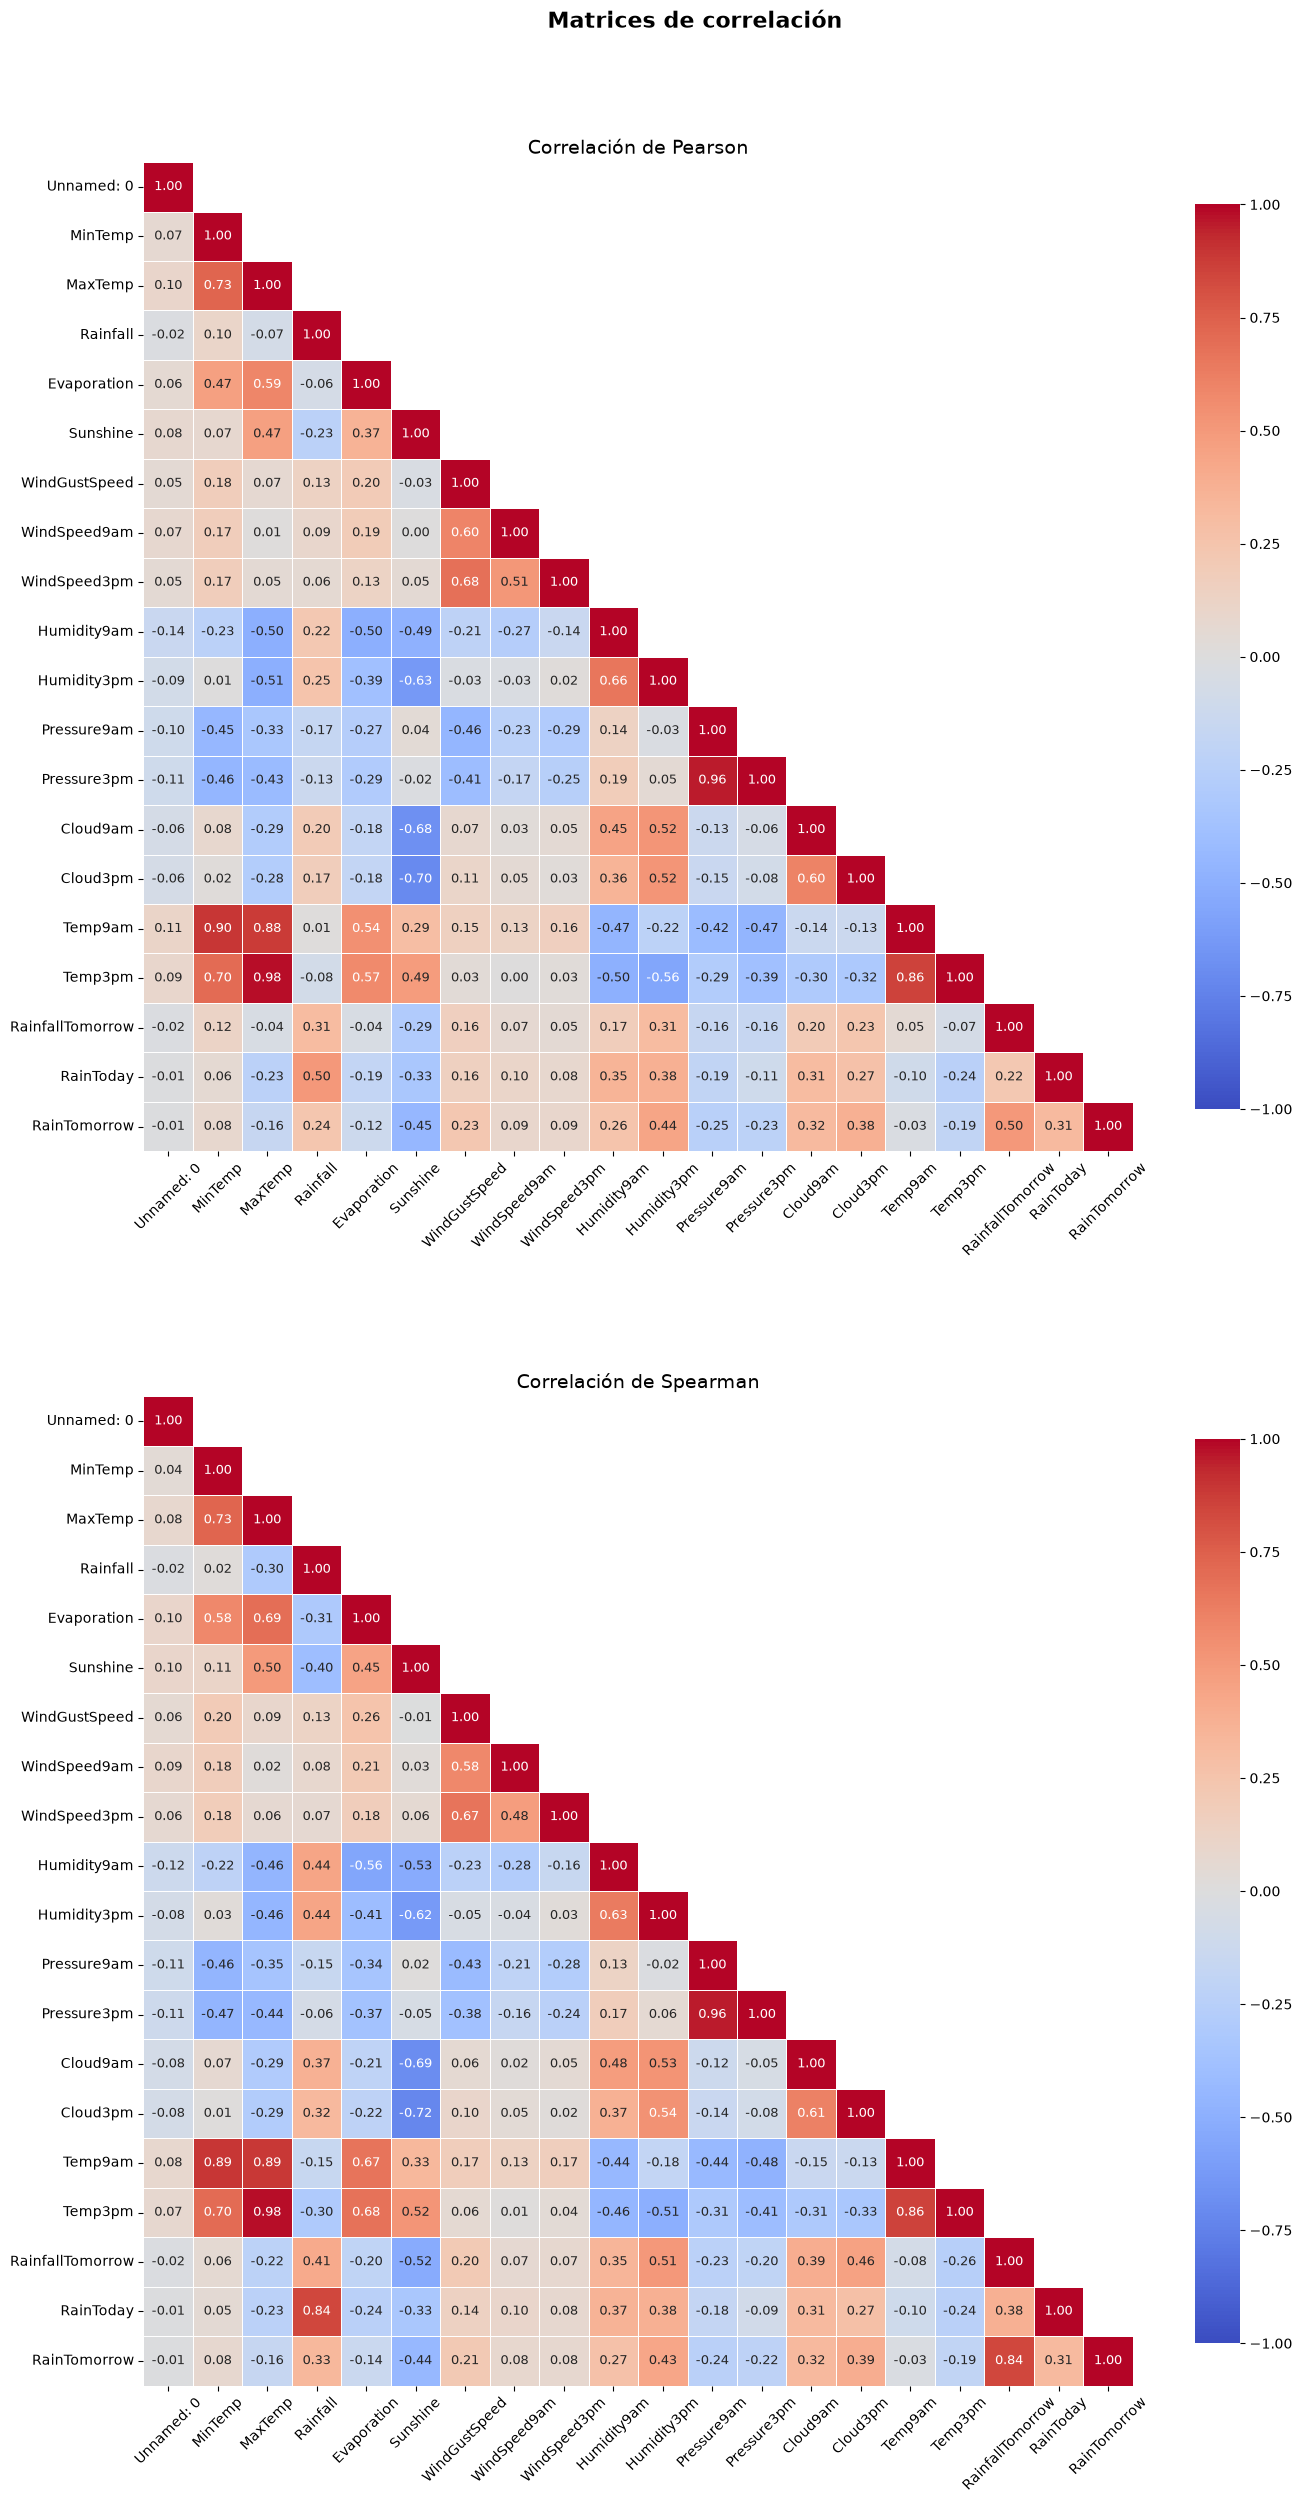

In [14]:
# Variables numéricas del dataset + binarias (Yes/No -> 1/0)
df_num = df.select_dtypes(include='number').copy()
for col in ['RainToday', 'RainTomorrow']:
    df_num[col] = df[col].map({'No': 0, 'Yes': 1})

# ---------- Matrices de correlación: Pearson y Spearman (una debajo de la otra) ----------
fig, axes = plt.subplots(2, 1, figsize=(14, 26))
fig.suptitle('Matrices de correlación', fontsize=16, fontweight='bold')

for ax, metodo in zip(axes, ['pearson', 'spearman']):
    corr = df_num.corr(method=metodo)
    mascara = np.triu(np.ones_like(corr, dtype=bool), k=1)  # oculta el triángulo superior (redundante)
    sns.heatmap(corr, ax=ax, mask=mascara, annot=True, fmt='.2f', annot_kws={'size': 9},
                cmap='coolwarm', vmin=-1, vmax=1, square=True,
                linewidths=0.5, cbar_kws={'shrink': 0.8})
    ax.set_title(f'Correlación de {metodo.capitalize()}', fontsize=14)
    ax.tick_params(axis='x', rotation=45, labelsize=10)
    ax.tick_params(axis='y', rotation=0, labelsize=10)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

En base  a lo observado, podemos notar que hay variables muy fuertemente correlacionadas (+ del 96%):
- Temp3pm y MaxTemp
- Pressure3pm y Pressure9am

Hay algunas otras variables que presentan buenas correlaciones, ya sean positivas o negativas, aun que las anteriores son las más significativas.

Pero en general podemos concluir que la mayoría de las entradas no están correlacionadas entre sí ni con la variable objetivo.

##### 5. Gráfico de pares: scatters + histogramas en la diagonal

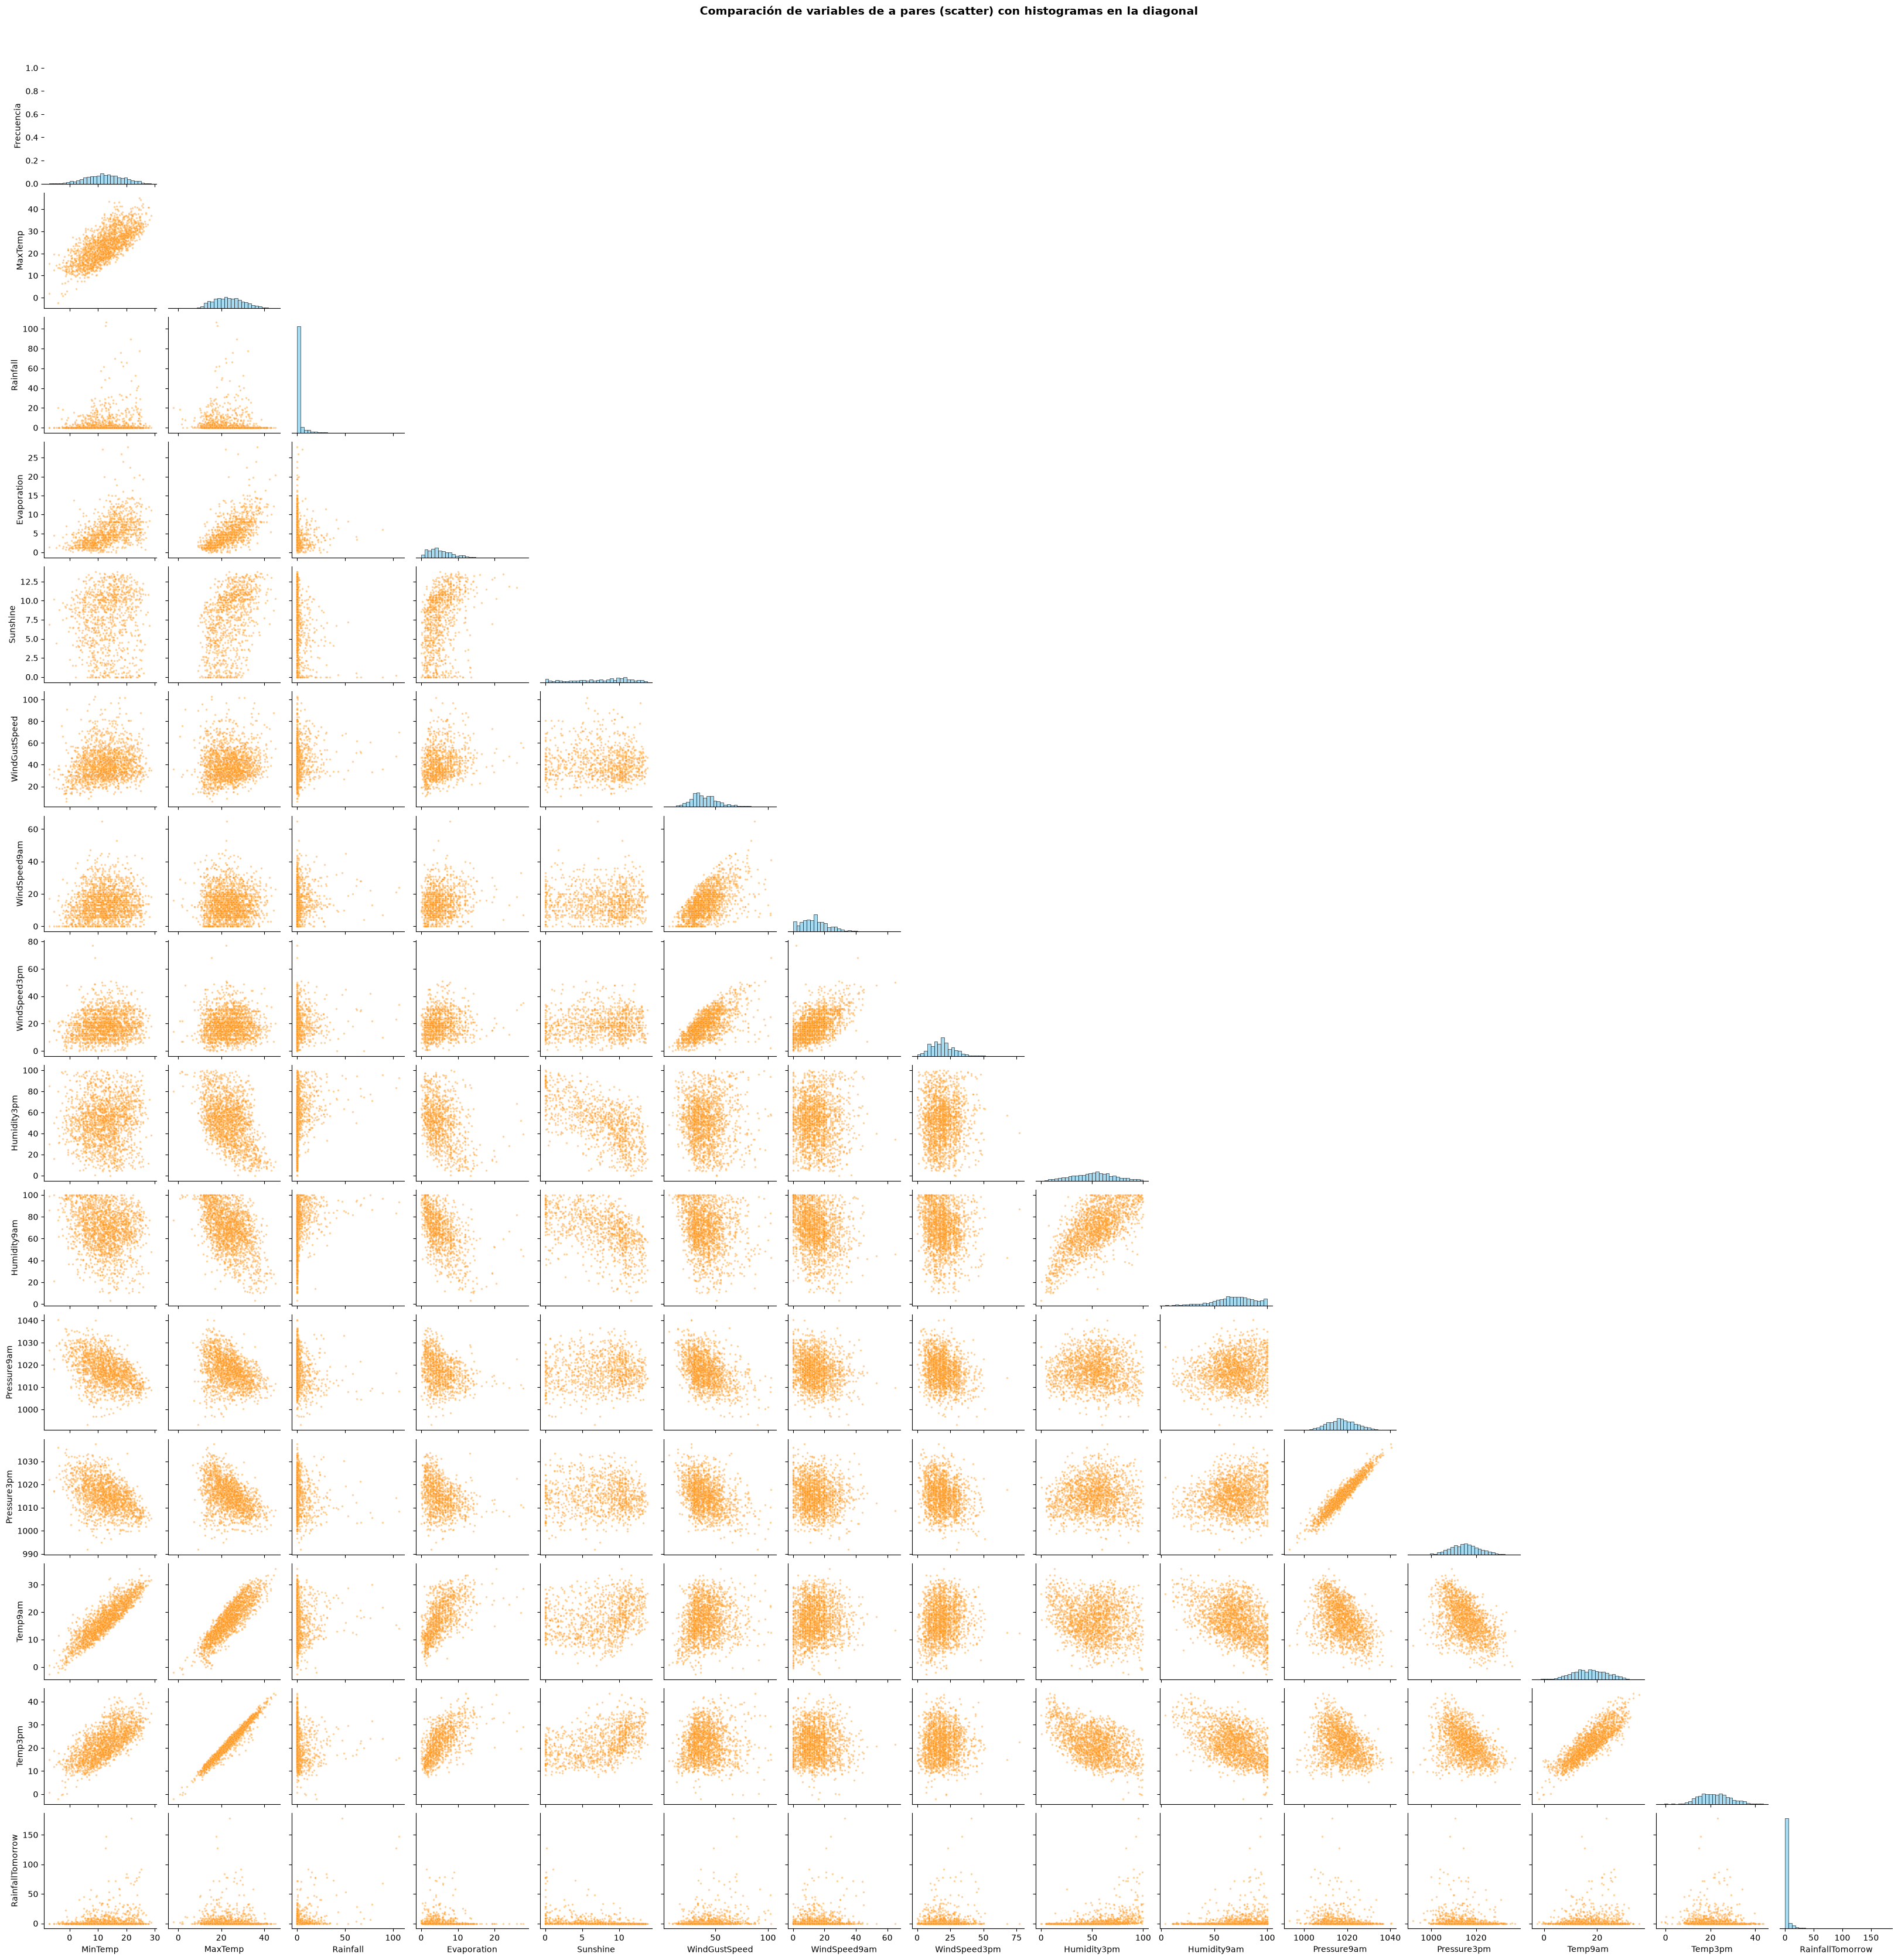

In [15]:
# Se excluyen: Unnamed: 0 (índice), RainToday y RainTomorrow (binarias), Location, WindGustDir, WindDir3pm y WindDir9am (categóricas),
# además de Cloud9am y Cloud3pm que son numericas discretas y no aportan información relevante para este gráfico.
variables_numericas_continuas = ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine',
                                 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity3pm', 
                                 'Humidity9am', 'Pressure9am', 'Pressure3pm', 'Temp9am', 'Temp3pm', 'RainfallTomorrow']

# Se usa una muestra para que el gráfico no tarde demasiado
muestra = df_num[variables_numericas_continuas].sample(n=min(2000, len(df_num)), random_state=42)

# corner=True muestra solo el triángulo inferior (cada par de variables aparece una única vez)
g = sns.pairplot(muestra, diag_kind='hist', corner=True,
                 plot_kws={'s': 6, 'alpha': 0.4, 'color': 'darkorange'},
                 diag_kws={'color': 'skyblue', 'edgecolor': 'black', 'bins': 30},
                 height=2.2)
# Con corner=True el primer histograma queda sin etiqueta en el eje Y; se agrega manualmente
g.axes[0, 0].set_ylabel('Frecuencia')
g.axes[0, 0].yaxis.set_visible(True)

g.fig.suptitle('Comparación de variables de a pares (scatter) con histogramas en la diagonal',
               y=1.02, fontsize=14, fontweight='bold')
plt.show()


Los scatterplots nos permiten ver la forma que dibujan las variables al relacionarse.

Podemos observar muy fuertes relaciones lineales en los pares:
- MaxTemp y Temp3pm
- Pressure3pm y Pressure9am
lo que coindide exactamente con lo que vimos en las matrices de correlaciones.

Otras variables relacionadas linealmente (que tambien tienen fuertes correlaciones en las matrices de Pearson y Spearman) son:
- Temp9am y MinTemp
- Temp9am y MaxTemp
- Temp3pm y Temp9am.
Seguidas de unos comportamientos lineales un poco más difuminados:
- MaxTemp y MinTemp
- Temp3pm y MinTemp


##### 6. Geolocalizacion
Para más adelante utilizar el método KNN, evaluando la cercanía de las locaciones a analizar, procedemos a explayar la informacion que tenemos de las ciudades encuestadas a través de la identificacion de sus latitudes y longitudes. Generaremos un gráfico para visualizar los resultados obtenidos en un año particular.


In [48]:
# Extraemos valores únicos para hacer una unica peticion por cada ciudad que aparece
ciudades_unicas = df['Location'].dropna().unique()

# Inicializamos el geocodificador
geolocator = ArcGIS()
lista_coordenadas = []

# Consultamos la API de forma segura
for ciudad in ciudades_unicas:
    # Concatenamos ", Australia" para evitar que el geocoder devuelva ciudades homónimas de otros países
    query = f"{ciudad}, Australia"
    try:
        # El timeout=10 evita que el script se cuelgue infinitamente si hay un microcorte de red
        loc = geolocator.geocode(query, timeout=10)
        if loc:
            lista_coordenadas.append({
                'Location': ciudad,
                'Latitud': loc.latitude,
                'Longitud': loc.longitude})
        else:
            lista_coordenadas.append({
                'Location': ciudad,
                'Latitud': None,
                'Longitud': None})
            print(f"  [!] No se encontraron coordenadas para: {ciudad}")
    except Exception as e:
        print(f"  [X] Error de conexión con {ciudad}: {e}")
        # Insertamos nulos para mantener la consistencia del merge posterior
        lista_coordenadas.append({'Location': ciudad, 'Latitud': None, 'Longitud': None})
    # Pausa de cortesía (0.2s es ideal para no saturar su servidor)
    time.sleep(0.2)

# Convertir la lista de diccionarios a un DataFrame de mapeo
df_mapa_coords = pd.DataFrame(lista_coordenadas)

# Unir (Merge) las coordenadas al dataset original
# Usamos how='left' sobre la columna 'Location' para garantizar que:
# - No se pierda ninguna fila original (incluso si falló su geolocalización)
# - La columna 'Location' se mantenga exactamente igual
df_mapa = df.merge(df_mapa_coords, on='Location', how='left')

'''Para el gráfico tomamos un año de ejemplo: 2016, ya que es el último año con datos completos.
Para ello reclasificamos la columna de fecha para identificar meses y años; tambien útil para metodos posteriores:'''
# Pasamos a datetime la columna 'Date' para poder extraer año y mes
df_mapa['Date'] = pd.to_datetime(df_mapa['Date'], errors='coerce')
# Extraer el año usando el accesor vectorial '.dt'
df_mapa['Year'] = df_mapa['Date'].dt.year
# Extraer el mes para ver estacionalidad
df_mapa['Month'] = df_mapa['Date'].dt.month
# Filtramos los datos específicamente para el año 2016 (es el año más reciente que está completo)
año_objetivo = 2016
df_filtrado = df_mapa[df_mapa['Year'] == año_objetivo]

# Agrupamos por ciudad ('Location') para calcular el acumulado total de lluvia
# También mantenemos la primera ocurrencia de Latitud y Longitud para el mapa
df_mapa = df_filtrado.groupby('Location').agg({
    'Rainfall': lambda s: s.sum(min_count=1),  # Suma de la lluvia medida del año (los NaN se ignoran; sin ningún dato -> NaN)
    'Latitud': 'first',     # Conservamos su latitud
    'Longitud': 'first'     # Conservamos su longitud
}).reset_index()

# Descartamos las ciudades sin ninguna medición de lluvia ese año (en vez de contarlas como 0)
df_mapa = df_mapa.dropna(subset=['Rainfall'])

# Mostrar una vista previa de los acumulados calculados
display(df_mapa.head())

,Location,Rainfall,Latitud,Longitud
0,Adelaide,820.8,-34.925704,138.596147
1,Albany,914.5,-35.025111,117.883784
2,Albury,805.0,-36.080812,146.915846
3,AliceSprings,373.2,-23.697469,133.884171
4,BadgerysCreek,664.6,-33.877527,150.744429


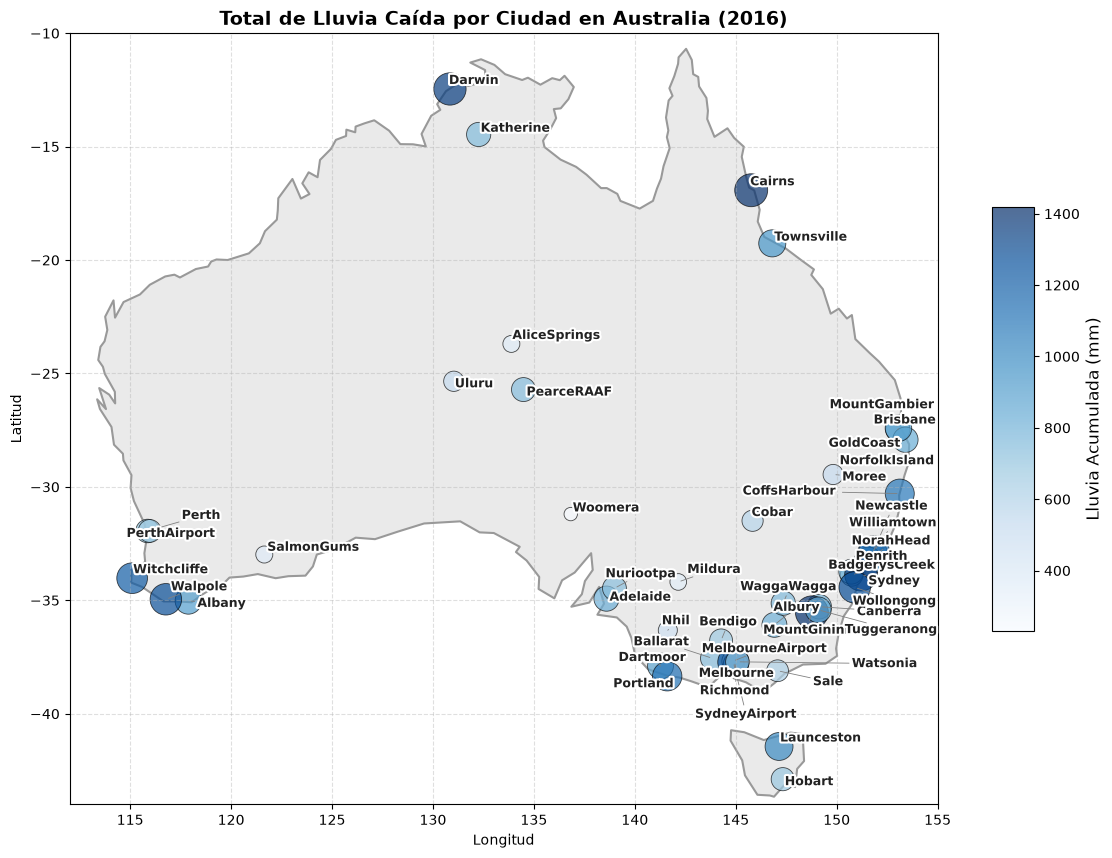

In [49]:
# A continuación generamos el grafico de mapa:

# 1. Obtener la silueta de los países descargándola directamente desde una URL pública confiable
# Esto evita el error de depreciación de geopandas.datasets en versiones >= 1.0
url_mapa_mundial = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_110m_admin_0_countries.geojson"
world = gpd.read_file(url_mapa_mundial)

# 2. Filtrar el mapa del mundo para quedarnos únicamente con Australia
# En el dataset completo de Natural Earth el nombre suele venir en la columna 'NAME'
australia = world[world['NAME'] == "Australia"]

# Si por alguna razón la columna viene como 'name', usamos un respaldo preventivo:
if australia.empty:
    australia = world[world['name'] == "Australia"]

# 3. Crear la figura
fig, ax = plt.subplots(figsize=(14, 11))

# 4. Dibujar el contorno físico de Australia de fondo (color gris claro con bordes definidos)
australia.plot(ax=ax, color='#EAEAEA', edgecolor='#999999', linewidth=1.5)

# 5. Graficar los datos de lluvia sobre el contorno físico
# Puntos más chicos y semitransparentes para no tapar las etiquetas
datos = df_mapa.dropna(subset=['Latitud', 'Longitud'])
sc = ax.scatter(
    datos['Longitud'], datos['Latitud'],
    s=datos['Rainfall'] * 0.4,
    c=datos['Rainfall'],
    cmap='Blues',
    alpha=0.7,
    edgecolors='black',
    linewidth=0.6)

# 6. Añadir barra de color
cbar = plt.colorbar(sc, ax=ax, shrink=0.5, aspect=10)
cbar.set_label('Lluvia Acumulada (mm)', fontsize=12)

# Zoom a la zona donde están las estaciones
ax.set_xlim(112, 155)
ax.set_ylim(-44, -10)

# 7. Etiquetas de todas las ciudades, con halo blanco para que se lean sobre los puntos
halo = [pe.withStroke(linewidth=3, foreground='white')]
textos = [
    ax.text(row['Longitud'], row['Latitud'], row['Location'],
            fontsize=9, weight='bold', color='#222222', path_effects=halo)
    for _, row in datos.iterrows()]

# Reubica las etiquetas para que no se pisen y las une al punto con una línea
adjust_text(textos, ax=ax, arrowprops=dict(arrowstyle='-', color='gray', lw=0.6))

plt.title(f'Total de Lluvia Caída por Ciudad en Australia ({año_objetivo})', fontsize=14, fontweight='bold')
plt.xlabel('Longitud', fontsize=10)
plt.ylabel('Latitud', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()

Conclusiones en base a este mapa:
- La lluvia se concentra en la costa, sobre todo en el este y sudeste, y el interior es más seco. Es el patrón climático esperable de Australia.
- Hay diferencias grandes entre ciudades cercanas. Esto sugiere que Location aporta información útil para predecir RainTomorrow. 

### Limpieza

#### 1. 'Unnamed: 0' -> eliminación

La primer columna, 'Unnamed: 0', representa el índice del dataset. Pero al examinarla detalladamente notamos que hay valores erroneos dentro de ella (no consecutivos, salteo, etc).
Existen 2 opciones: eliminarla y crearla nuevamente para que se respete el orden de las filas; o bien eliminarla definitivamente. SAeguiremos esta segunda opcion, ya que para el analisis posterior no será necesaria esta información.

In [18]:
df.drop(columns="Unnamed: 0", inplace=True)

df.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
0,2008-12-01,Albury,13.6,22.5,0.6,NaN,NaN,W,45.0,W,...,23.8,1008.1,1007.2,8.0,NaN,16.8,20.8,No,No,0.0
1,2008-12-02,Albury,7.3,25.8,0.0,NaN,NaN,WNW,44.0,NNW,...,22.1,1011.1,1007.5,NaN,NaN,18.3,24.6,No,No,0.0
2,2008-12-03,Albury,13.2,26.2,0.0,NaN,NaN,WSW,46.0,W,...,31.5,1007.3,1009.4,NaN,2.0,21.2,23.4,No,No,0.0
3,2008-12-04,Albury,10.0,28.8,0.0,NaN,NaN,NE,23.0,SE,...,18.5,1017.6,1012.4,NaN,NaN,17.4,26.3,No,No,1.0
4,2008-12-05,Albury,17.4,32.4,1.0,NaN,NaN,W,41.0,ENE,...,34.6,1010.9,1005.9,7.0,8.0,17.9,29.1,No,No,0.2


#### 2. 'Location' -> reemplazo por Latitud y Longitud
Reemplazamos la variable Locacion y la cambiamos por su latitud y longitud, con ls que podemnos comparar las variables ya que guardan una relacion entre sí.

In [19]:
# Agregamos Latitud y Longitud a df a partir de las coordenadas por ciudad
# Usamos df_mapa_coords
coords = df_mapa_coords[['Location', 'Latitud', 'Longitud']].copy()
# Ambas columnas 'Location' deben tener el mismo tipo para poder unirlas
coords['Location'] = coords['Location'].astype(df['Location'].dtype)

df = df.merge(coords, on='Location', how='left')

# Ya con las coordenadas incorporadas, 'Location' no es necesaria
df.drop(columns='Location', inplace=True)

df.head()

,Date,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,...,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow,Latitud,Longitud
0,2008-12-01,13.6,22.5,0.6,NaN,NaN,W,45.0,W,WNW,...,1007.2,8.0,NaN,16.8,20.8,No,No,0.0,-36.080812,146.915846
1,2008-12-02,7.3,25.8,0.0,NaN,NaN,WNW,44.0,NNW,WSW,...,1007.5,NaN,NaN,18.3,24.6,No,No,0.0,-36.080812,146.915846
2,2008-12-03,13.2,26.2,0.0,NaN,NaN,WSW,46.0,W,WSW,...,1009.4,NaN,2.0,21.2,23.4,No,No,0.0,-36.080812,146.915846
3,2008-12-04,10.0,28.8,0.0,NaN,NaN,NE,23.0,SE,E,...,1012.4,NaN,NaN,17.4,26.3,No,No,1.0,-36.080812,146.915846
4,2008-12-05,17.4,32.4,1.0,NaN,NaN,W,41.0,ENE,NW,...,1005.9,7.0,8.0,17.9,29.1,No,No,0.2,-36.080812,146.915846


##### 3. Codificacion circular de variables
La siguiente información podría clasificarse solo como fecha o bien como categórica:
- los 12 meses de cada año ('Date')
- WindgustDir, WindDir9am, WindDir3pm

pero en verdad siguen un patron circular: los meses, al finalizar diciembre (12), reinician en un nuevo año; y en los casos de la direcicon del viento, Norte y Oeste estan más cercamos entre sí que Norte y Sur por ejemplo.
Por esta razon procedemos a aplicar a estas columnas la *Codificacion cıclica*

##### - Date
Aplicaremos la codificación unicamente al mes.
Separamos las informaciones de días y años, que al ser numericos y respetar un orden ordinal, no necesitan ser codificados, con el mes es suficiente.

In [20]:
# Extraer el año usando el accesor vectorial '.dt'
df['Year'] = df['Date'].dt.year

# Extraer el mes
df['Month'] = df['Date'].dt.month

# Extraer el día
df['Day'] = df['Date'].dt.day

# Eliminamos la columna Date ya que esa información ya fue extraída
df.drop(columns='Date', inplace=True)

In [21]:
meses = ['Enero', 'Febrero', 'Marzo', 'Abril', 'Mayo', 'Junio',
         'Julio', 'Agosto', 'Septiembre', 'Octubre', 'Noviembre', 'Diciembre']

# Cada mes → 30 grados * su posición (Enero = 0°, Febrero = 30°, ..., Diciembre = 330°)
grados_por_mes = {mes: i * 360 / len(meses) for i, mes in enumerate(meses)}

# Le asignamos el numero correspondiente al cada mes
df['Month'] = df['Month'].map(dict(enumerate(meses, start=1)))
# Agregamos una columna nueva codificando los meses con los grados correspondientes
df['Grades'] = df['Month'].map(grados_por_mes)

# Aplicamos seno y coseno
df['Month_sin'] = np.sin(np.deg2rad(df['Grades'])).round(4)
df['Month_cos'] = np.cos(np.deg2rad(df['Grades'])).round(4)

# Una vez hecho todo esto, ya podemos eliminar las columnas que creamos para el proceso
columnas = ['Month', 'Grades']
df.drop(columns=columnas, inplace=True)

In [22]:
# Chequeamos que los cambios se hayan plasmado
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 145412 entries, 0 to 145411
Data columns (total 28 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   MinTemp           143928 non-null  float64
 1   MaxTemp           144159 non-null  float64
 2   Rainfall          142152 non-null  float64
 3   Evaporation       82658 non-null   float64
 4   Sunshine          75616 non-null   float64
 5   WindGustDir       135096 non-null  str    
 6   WindGustSpeed     135159 non-null  float64
 7   WindDir9am        134850 non-null  str    
 8   WindDir3pm        141186 non-null  str    
 9   WindSpeed9am      143645 non-null  float64
 10  WindSpeed3pm      142351 non-null  float64
 11  Humidity9am       142759 non-null  float64
 12  Humidity3pm       140907 non-null  float64
 13  Pressure9am       130351 non-null  float64
 14  Pressure3pm       130388 non-null  float64
 15  Cloud9am          89542 non-null   float64
 16  Cloud3pm          86076 non-nul

In [23]:
df.head()

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,...,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow,Latitud,Longitud,Year,Day,Month_sin,Month_cos
0,13.6,22.5,0.6,NaN,NaN,W,45.0,W,WNW,19.0,...,20.8,No,No,0.0,-36.080812,146.915846,2008,1,-0.5,0.866
1,7.3,25.8,0.0,NaN,NaN,WNW,44.0,NNW,WSW,4.0,...,24.6,No,No,0.0,-36.080812,146.915846,2008,2,-0.5,0.866
2,13.2,26.2,0.0,NaN,NaN,WSW,46.0,W,WSW,20.0,...,23.4,No,No,0.0,-36.080812,146.915846,2008,3,-0.5,0.866
3,10.0,28.8,0.0,NaN,NaN,NE,23.0,SE,E,10.0,...,26.3,No,No,1.0,-36.080812,146.915846,2008,4,-0.5,0.866
4,17.4,32.4,1.0,NaN,NaN,W,41.0,ENE,NW,6.0,...,29.1,No,No,0.2,-36.080812,146.915846,2008,5,-0.5,0.866


##### - WindgustDir, WindDir9am, WindDir3pm

In [24]:
puntos_cardinales = ['N', 'NNE', 'NE', 'ENE', 'E', 'ESE', 'SE', 'SSE',
                     'S', 'SSW', 'SW', 'WSW', 'W', 'WNW', 'NW', 'NNW']

# Cada dirección → 22.5 grados * su posición (N = 0°, NNE = 22.5°, ..., NNW = 337.5°)
grados_por_direccion = {d: i * 360 / len(puntos_cardinales) for i, d in enumerate(puntos_cardinales)}

columnas_viento = ['WindGustDir', 'WindDir9am', 'WindDir3pm']

for col in columnas_viento:
    # Los NaN quedan como NaN al mapear, y se propagan a seno y coseno (se imputan más adelante)
    grados = df[col].map(grados_por_direccion)

    # Aplicamos seno y coseno
    df[f'{col}_sin'] = np.sin(np.deg2rad(grados)).round(4)
    df[f'{col}_cos'] = np.cos(np.deg2rad(grados)).round(4)

# Eliminamos las columnas categóricas originales, ya reemplazadas por su codificación
df.drop(columns=columnas_viento, inplace=True)

In [25]:
# Chequeamos que los cambios se hayan plasmado
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 145412 entries, 0 to 145411
Data columns (total 31 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   MinTemp           143928 non-null  float64
 1   MaxTemp           144159 non-null  float64
 2   Rainfall          142152 non-null  float64
 3   Evaporation       82658 non-null   float64
 4   Sunshine          75616 non-null   float64
 5   WindGustSpeed     135159 non-null  float64
 6   WindSpeed9am      143645 non-null  float64
 7   WindSpeed3pm      142351 non-null  float64
 8   Humidity9am       142759 non-null  float64
 9   Humidity3pm       140907 non-null  float64
 10  Pressure9am       130351 non-null  float64
 11  Pressure3pm       130388 non-null  float64
 12  Cloud9am          89542 non-null   float64
 13  Cloud3pm          86076 non-null   float64
 14  Temp9am           143646 non-null  float64
 15  Temp3pm           141805 non-null  float64
 16  RainToday         142152 non-nu

In [26]:
df.head()

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,...,Year,Day,Month_sin,Month_cos,WindGustDir_sin,WindGustDir_cos,WindDir9am_sin,WindDir9am_cos,WindDir3pm_sin,WindDir3pm_cos
0,13.6,22.5,0.6,NaN,NaN,45.0,19.0,25.0,68.8,23.8,...,2008,1,-0.5,0.866,-1.0000,-0.0000,-1.0000,-0.0000,-0.9239,0.3827
1,7.3,25.8,0.0,NaN,NaN,44.0,4.0,23.0,40.1,22.1,...,2008,2,-0.5,0.866,-0.9239,0.3827,-0.3827,0.9239,-0.9239,-0.3827
2,13.2,26.2,0.0,NaN,NaN,46.0,20.0,27.0,36.2,31.5,...,2008,3,-0.5,0.866,-0.9239,-0.3827,-1.0000,-0.0000,-0.9239,-0.3827
3,10.0,28.8,0.0,NaN,NaN,23.0,10.0,10.0,45.8,18.5,...,2008,4,-0.5,0.866,0.7071,0.7071,0.7071,-0.7071,1.0000,0.0000
4,17.4,32.4,1.0,NaN,NaN,41.0,6.0,17.0,83.5,34.6,...,2008,5,-0.5,0.866,-1.0000,-0.0000,0.9239,0.3827,-0.7071,0.7071


#### 4. 'RainToday' -> OHE
Al ser una variable categorica dicotómica, utilizamos One Hot Encoding para ingresarla a nuetsro modelo.

In [27]:
df = pd.get_dummies(df, columns=['RainToday'], drop_first=True, dtype=int)

# Chequeamos
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 145412 entries, 0 to 145411
Data columns (total 31 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   MinTemp           143928 non-null  float64
 1   MaxTemp           144159 non-null  float64
 2   Rainfall          142152 non-null  float64
 3   Evaporation       82658 non-null   float64
 4   Sunshine          75616 non-null   float64
 5   WindGustSpeed     135159 non-null  float64
 6   WindSpeed9am      143645 non-null  float64
 7   WindSpeed3pm      142351 non-null  float64
 8   Humidity9am       142759 non-null  float64
 9   Humidity3pm       140907 non-null  float64
 10  Pressure9am       130351 non-null  float64
 11  Pressure3pm       130388 non-null  float64
 12  Cloud9am          89542 non-null   float64
 13  Cloud3pm          86076 non-null   float64
 14  Temp9am           143646 non-null  float64
 15  Temp3pm           141805 non-null  float64
 16  RainTomorrow      142153 non-nu

In [28]:
df.head()

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,...,Day,Month_sin,Month_cos,WindGustDir_sin,WindGustDir_cos,WindDir9am_sin,WindDir9am_cos,WindDir3pm_sin,WindDir3pm_cos,RainToday_Yes
0,13.6,22.5,0.6,NaN,NaN,45.0,19.0,25.0,68.8,23.8,...,1,-0.5,0.866,-1.0000,-0.0000,-1.0000,-0.0000,-0.9239,0.3827,0
1,7.3,25.8,0.0,NaN,NaN,44.0,4.0,23.0,40.1,22.1,...,2,-0.5,0.866,-0.9239,0.3827,-0.3827,0.9239,-0.9239,-0.3827,0
2,13.2,26.2,0.0,NaN,NaN,46.0,20.0,27.0,36.2,31.5,...,3,-0.5,0.866,-0.9239,-0.3827,-1.0000,-0.0000,-0.9239,-0.3827,0
3,10.0,28.8,0.0,NaN,NaN,23.0,10.0,10.0,45.8,18.5,...,4,-0.5,0.866,0.7071,0.7071,0.7071,-0.7071,1.0000,0.0000,0
4,17.4,32.4,1.0,NaN,NaN,41.0,6.0,17.0,83.5,34.6,...,5,-0.5,0.866,-1.0000,-0.0000,0.9239,0.3827,-0.7071,0.7071,0


#### 5. Filtrado de variables correlacionadas
Las variables más correlacionadas entre sí, como mencionamos anteriormente, son: 
- Temp3pm y MaxTemp
- Pressure3pm y Pressure9am

Las 4 tienen muy baja correlacion con la variable a predecir, por lo que no hay una preferida a la hora de deshacernos de alguna (para bajarle dimensionalidad al problema).

Decidimos que utilizaremos como método de seleccion la cuenta de datos faltantes. Según nuestro último .info():
- Temp3pm           141805 non-null
- MaxTemp           144159 non-null

- Pressure9am       130351 non-null
- Pressure3pm       130388 non-null

Por lo tanto Nos quedaremos con MaxTemp y Pressure3pm, deshaciendonos de las otras 2.

In [29]:
df = df.drop(columns=['Temp3pm', 'Pressure9am'])

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 145412 entries, 0 to 145411
Data columns (total 29 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   MinTemp           143928 non-null  float64
 1   MaxTemp           144159 non-null  float64
 2   Rainfall          142152 non-null  float64
 3   Evaporation       82658 non-null   float64
 4   Sunshine          75616 non-null   float64
 5   WindGustSpeed     135159 non-null  float64
 6   WindSpeed9am      143645 non-null  float64
 7   WindSpeed3pm      142351 non-null  float64
 8   Humidity9am       142759 non-null  float64
 9   Humidity3pm       140907 non-null  float64
 10  Pressure3pm       130388 non-null  float64
 11  Cloud9am          89542 non-null   float64
 12  Cloud3pm          86076 non-null   float64
 13  Temp9am           143646 non-null  float64
 14  RainTomorrow      142153 non-null  str    
 15  RainfallTomorrow  142153 non-null  float64
 16  Latitud           145412 non-nu

In [30]:
df.head()

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,...,Day,Month_sin,Month_cos,WindGustDir_sin,WindGustDir_cos,WindDir9am_sin,WindDir9am_cos,WindDir3pm_sin,WindDir3pm_cos,RainToday_Yes
0,13.6,22.5,0.6,NaN,NaN,45.0,19.0,25.0,68.8,23.8,...,1,-0.5,0.866,-1.0000,-0.0000,-1.0000,-0.0000,-0.9239,0.3827,0
1,7.3,25.8,0.0,NaN,NaN,44.0,4.0,23.0,40.1,22.1,...,2,-0.5,0.866,-0.9239,0.3827,-0.3827,0.9239,-0.9239,-0.3827,0
2,13.2,26.2,0.0,NaN,NaN,46.0,20.0,27.0,36.2,31.5,...,3,-0.5,0.866,-0.9239,-0.3827,-1.0000,-0.0000,-0.9239,-0.3827,0
3,10.0,28.8,0.0,NaN,NaN,23.0,10.0,10.0,45.8,18.5,...,4,-0.5,0.866,0.7071,0.7071,0.7071,-0.7071,1.0000,0.0000,0
4,17.4,32.4,1.0,NaN,NaN,41.0,6.0,17.0,83.5,34.6,...,5,-0.5,0.866,-1.0000,-0.0000,0.9239,0.3827,-0.7071,0.7071,0


#### 5. Datos faltantes
Inicialmente chequeamos cuántos datos faltantes tenemos actualmente despues de la limpieza que efectuamos:

In [31]:
with pd.option_context('display.max_rows', None):
    display(pd.DataFrame({
        'no_nulos': df.count(),
        'nulos': df.isna().sum(),
        'dtype': df.dtypes,
        '%_nulos': (df.isna().mean() * 100).round(2)}))

,no_nulos,nulos,dtype,%_nulos
MinTemp,143928,1484,float64,1.02
MaxTemp,144159,1253,float64,0.86
Rainfall,142152,3260,float64,2.24
Evaporation,82658,62754,float64,43.16
Sunshine,75616,69796,float64,48.00
WindGustSpeed,135159,10253,float64,7.05
WindSpeed9am,143645,1767,float64,1.22
WindSpeed3pm,142351,3061,float64,2.11
Humidity9am,142759,2653,float64,1.82
Humidity3pm,140907,4505,float64,3.10


Primero eliminamos todas aquellas filas que posean Nan en la variable a predecir:

In [32]:
n_inicial = len(df)
n_antes = len(df)
df = df.dropna(subset=['RainTomorrow', 'RainfallTomorrow'])
n_despues = len(df)

print(f"Filas eliminadas: {n_antes - n_despues} de {n_antes} ({(n_antes - n_despues) / n_antes:.2%} del total)")

Filas eliminadas: 3259 de 145412 (2.24% del total)


Una vez obtenido el porcentaje de eliminados, sabemos qwue podemos seguir haciendo limpieza de nulos hasta un 2,25% mas aproximadamente (para no eliminar más del 5% de los datos totales):

In [33]:
pct_nan = df.isna().mean(axis=1)
for u in [0.2, 0.25, 0.3, 0.4, 0.5]:
    print(f"umbral {u:.0%}: se eliminan {(pct_nan > u).sum()} filas ({(pct_nan > u).mean():.2%})")

umbral 20%: se eliminan 9999 filas (7.03%)
umbral 25%: se eliminan 4370 filas (3.07%)
umbral 30%: se eliminan 3014 filas (2.12%)
umbral 40%: se eliminan 1398 filas (0.98%)
umbral 50%: se eliminan 253 filas (0.18%)


In [34]:
n_antes = len(df)
df = df[df.isna().mean(axis=1) <= 0.3]
n_despues = len(df)

print(f"Filas eliminadas: {n_antes - n_despues} de {n_antes} ({(n_antes - n_despues) / n_antes:.2%} del total)")

Filas eliminadas: 3014 de 142153 (2.12% del total)


In [35]:
# Corroboramos que los datos eliminados sean hasta 5% del total
n_despues/n_inicial * 100

95.68605066982092

Observamos que el dataset aun conserva más de un 95% de la data original.

##### Estandarización/Escalado de datos - Imputacion de valores faltantes -> KNN

In [ ]:
# Separar las variables predictoras de la variable objetivo
### Eliminamos además RainfallTomorrow porque brinda información del futuro (data leakage)
X = df.drop(columns=['RainTomorrow', 'RainfallTomorrow'])
y = df['RainTomorrow']

# Separar los datos en entrenamiento (70%), validación (15%) y prueba (15%)
### Usamos stratify para que los 3 conjuntos 'Yes' y 'No'
### de la variable objetivo mantengan la misma proporción de clases.
# 1) 70% train y 30% restante (temporal)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)
# 2) El 30% restante se divide a la mitad: 15% validación y 15% prueba
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

# Columnas con muchísimos nulos (~40-48%).
# Usamos SimpleImputer (mediana) y no KNN por dos motivos:
#   1) Con casi la mitad de los datos faltantes, los "vecinos" casi no tienen
#      información real para estimar el valor: KNN terminaría inventando valores
#      a partir de otros ya imputados, sin aportar más que la mediana.
#   2) Costo computacional: gran parte de las filas tiene nulos en estas columnas,
#      por lo que KNN debería calcular distancias contra ~116.000 filas por cada
#      fila a imputar (O(n²)), haciendo que la celda tarde muchísimo.
cols_mediana = ['Evaporation', 'Sunshine', 'Cloud9am', 'Cloud3pm']
# El resto de columnas tiene pocos nulos, ahí KNN es confiable
cols_knn = [c for c in X_train.columns if c not in cols_mediana]

# 1) Imputación por mediana (calculada solo con train para evitar data leakage)
imputer_mediana = SimpleImputer(strategy='median')
X_train[cols_mediana] = imputer_mediana.fit_transform(X_train[cols_mediana])
X_val[cols_mediana] = imputer_mediana.transform(X_val[cols_mediana])
X_test[cols_mediana] = imputer_mediana.transform(X_test[cols_mediana])

# 2) Estandarización de las columnas restantes (KNN usa distancias, por lo que
#    necesita que todas las variables estén en la misma escala)
scaler = StandardScaler()
X_train_knn = scaler.fit_transform(X_train[cols_knn])
X_val_knn = scaler.transform(X_val[cols_knn])
X_test_knn = scaler.transform(X_test[cols_knn])

# 3) Imputación KNN.
# Ajustamos el imputador con una muestra aleatoria de train (10.000 filas):
# esas filas son el "pool" de donde se eligen los vecinos. Así el costo baja
# ~10 veces y la estimación es prácticamente la misma.
rng = np.random.RandomState(42)
idx_muestra = rng.choice(X_train_knn.shape[0], size=10000, replace=False)

knn_imputer = KNNImputer(n_neighbors=5)
knn_imputer.fit(X_train_knn[idx_muestra])
X_train_knn = knn_imputer.transform(X_train_knn)
X_val_knn = knn_imputer.transform(X_val_knn)
X_test_knn = knn_imputer.transform(X_test_knn)

# 4) Revertimos la estandarización para volver a la escala original
X_train[cols_knn] = scaler.inverse_transform(X_train_knn)
X_val[cols_knn] = scaler.inverse_transform(X_val_knn)
X_test[cols_knn] = scaler.inverse_transform(X_test_knn)

##### Explicacion de decisiones tomadas:

##### *¿Por qué usamos SimpleImputer para las variables Evaporation, Sunshine, Cloud3pm y Cloud9am?*
Porque las 4 poseen entre 38 y 50% de faltantes. KNN recibía poca información para trabajar, así que las estimaciones no eran buenas y además el costo computacional y de tiempo era muy grande (horas de ejecucion).
Por ende, Evaporation, Sunshine, Cloud3pm y Cloud9am se imputan con la mediana.

##### *¿Por qué seleccionamos 10.000 filas para imputar y no todas?*
| Donantes            | Tiempo estimado (train completo) |
|--------------------|----------------------------------|
| 2.000              | ~11 s                            |
| 5.000              | ~26 s                            |
| 10.000             | ~50 s a 1,5 min                 |
| ~91.000 (todo train) | ~8 a 15 min                    |

El tiempo crece linealmente con los donantes (filas que toma knn para imputar). 
Usar todo train es unas 9 veces más lento que usar 10.000. 

- Es una decisión de costo computacional, no de calidad. KNN es O(n × m): cada fila con nulos se compara con todos los donantes. Con todo train, la celda tarda minutos.
- 10.000 filas son una muestra representativa. Es aleatoria (random_state=42, reproducible) y con ese tamaño las distribuciones coinciden con las de train. Para estimar un valor a partir de 5 vecinos cercanos, el pool de 10.000 ya contiene vecinos muy parecidos.
- Las variables con más nulos no pasan por KNN. Evaporation, Sunshine, Cloud9am y Cloud3pm tienen ~40-48 % de nulos y se imputan con la mediana. Con tantos faltantes los vecinos aportarían poco.


###  Modelo de regresión logística
Creamos un modelo de regresión logística, el cual estima una probabilidad de lluvia entre 0 y 1

*   y_pred devuelve las clases predichas (0 o 1), usando por defecto un umbral de 0,5.
*   p_prob devuelve las probabilidades estimadas. La segunda columna corresponde a la clase 1 si las clases están ordenadas como 0, 1.

Utilizaremos: y_pred para varias métricas y la matriz de confusión, y y_prob para la curva ROC y el análisis de umbrales.


In [37]:
# Crear el modelo
modelo = LogisticRegression(max_iter=1000)

# Entrenar con los datos de entrenamiento
modelo.fit(X_train, y_train)

# Predecir las clases sobre el conjunto de validación
# (el conjunto de prueba se reserva para la evaluación final)
y_pred_val = modelo.predict(X_val)

# Obtener probabilidades de lluvia sobre validación
y_prob_val = modelo.predict_proba(X_val)[:, 1]


NameError: name 'LogisticRegression' is not defined

### Métricas de evaluación

* Accuracy:	¿Qué proporción del total de predicciones fue correcta?

* Precision:	De los días que predijimos con lluvia, ¿en cuántos llovió realmente?

* Recall:	De los días en que realmente llovió, ¿cuántos detectamos?

* F1-score:	¿Cómo se equilibra precision con recall?

* Balanced accuracy:	¿Qué tan bien reconoce tanto los días con lluvia como los días sin lluvia?

* ROC-AUC:	¿Qué tan bien distingue el modelo ambas clases al variar el umbral?

In [ ]:
# Métricas de evaluación (conjunto de validación)
print("Accuracy:", accuracy_score(y_val, y_pred_val))
print("Precision:", precision_score(y_val, y_pred_val, zero_division=0))
print("Recall:", recall_score(y_val, y_pred_val, zero_division=0))
print("F1-score:", f1_score(y_val, y_pred_val, zero_division=0))
print("Balanced accuracy:", balanced_accuracy_score(y_val, y_pred_val))
print("ROC-AUC:", roc_auc_score(y_val, y_prob_val))

### Graficar la matriz de confusión

* Falso negativo: el modelo anuncia que no va a llover, pero llueve. Puede ser  especialmente problemático si alguien depende del pronóstico para planificar una actividad al aire libre.

* Falso positivo: el modelo anuncia lluvia, pero no llueve. Puede llevar a cancelar o modificar innecesariamente una actividad.

In [ ]:
cm = confusion_matrix(y_val, y_pred_val, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No llueve", "Llueve"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión - Regresión logística (validación)")
plt.show()

### Trazar la curva ROC
La curva ROC muestra cómo cambia la capacidad de distinguir días lluviosos y no lluviosos cuando cambiamos el umbral de clasificación.

- Una curva más cerca de la esquina superior izquierda suele indicar una mejor discriminación.
- La diagonal representa el comportamiento de referencia de un clasificador aleatorio.
- Un ROC-AUC cercano a 1 indica buena capacidad de discriminación; uno cercano a 0,5 indica poca capacidad para distinguir las clases.
La curva ROC evalúa distintos umbrales, no solo el predeterminado de 0,5.

In [ ]:
fpr, tpr, thresholds = roc_curve(y_val, y_prob_val)
auc = roc_auc_score(y_val, y_prob_val)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Regresión logística (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Clasificador aleatorio")

plt.xlabel("Tasa de falsos positivos (FPR)")
plt.ylabel("Tasa de verdaderos positivos (TPR / Recall)")
plt.title("Curva ROC (validación)")
plt.legend()
plt.grid()
plt.show()

Si bajás el umbral, el modelo clasificará más días como lluviosos. En general:
- Aumentará el recall: detectará más días en que efectivamente llueve.
- También pueden aumentar los falsos positivos.
- La precision puede bajar.

Si subís el umbral, el modelo será más exigente para anunciar lluvia: generalmente disminuirán los falsos positivos, pero podrían aumentar los falsos negativos.

Una opción para calcular un umbral alternativo es buscar el umbral que maximiza el F1-score. Para hacerlo correctamente, usá un conjunto de validación o predicciones obtenidas mediante validación cruzada, no el conjunto de prueba final.

In [ ]:
# buscar el umbral que maximiza el F1-score

umbrales = np.arange(0.10, 0.91, 0.01)
f1_scores = []

for umbral in umbrales:
    predicciones = (y_prob_val >= umbral).astype(int)
    f1 = f1_score(y_val, predicciones, zero_division=0)
    f1_scores.append(f1)

mejor_indice = np.argmax(f1_scores)
mejor_umbral = umbrales[mejor_indice]

print("Mejor umbral:", mejor_umbral)
print("F1 máximo:", f1_scores[mejor_indice])

In [ ]:
# Evaluación final sobre el conjunto de prueba (usado una única vez),
# con el umbral elegido en validación
y_prob_test = modelo.predict_proba(X_test)[:, 1]
y_pred_test = (y_prob_test >= mejor_umbral).astype(int)

print("Umbral usado:", mejor_umbral)
print("Accuracy:", accuracy_score(y_test, y_pred_test))
print("Precision:", precision_score(y_test, y_pred_test, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_test, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred_test, zero_division=0))
print("Balanced accuracy:", balanced_accuracy_score(y_test, y_pred_test))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_test))


- Afecta el entrenamiento. Los modelos tienden a favorecer la clase mayoritaria. Según el caso se puede usar class_weight='balanced', ajustar el umbral de decisión, o hacer over/undersampling (por ejemplo SMOTE).